# Phase kickback, phase estimation, QFT and Shor's algorithm

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Broum/UKP_IQC_materials/blob/main/05_Qiskit_QPE_QFT_Shor.ipynb)

Content:
* Phase interferometer
* Phase kickback for a general controlled operation
* Controlled powers and the bits of a phase
* Quantum Fourier transform and its inverse
* Quantum phase estimation (QPE)
* Quantum counting
* Shor's algorithm

**How to use this notebook.** Most of the circuits here are short enough to build yourself. A cell after **Your turn** says what
we want and leaves the rest to you, with a collapsed solution below it. Try it first, the circuits have only a few lines. Nothing
later depends on your cell: the general versions we keep using are defined in the normal code cells.

The theory is in chapters *Phase kickback a odhad fáze* and *Kvantové počítání a Shorův algoritmus* of the
[textbook](https://homel.vsb.cz/~lam05/Teaching_files/UKP.pdf).

## 0. Setup

Same as in `01_Qiskit_intro_colab.ipynb`: in Colab the packages are installed per session, so uncomment and re-run
this cell after every runtime restart. For a local conda environment see that notebook.

In [ ]:
# %pip install -q qiskit qiskit-aer pylatexenc matplotlib sympy

In [2]:
import math
import random
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from scipy.linalg import expm
import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import QFTGate, UnitaryGate, ZGate, grover_operator, phase_estimation
from qiskit.quantum_info import Statevector, Operator, SparsePauliOp, partial_trace, random_unitary
from qiskit.visualization import plot_histogram, plot_bloch_multivector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, thermal_relaxation_error
from IPython.display import display, HTML

print(qiskit.__version__)

shots = 4096
sim = AerSimulator()


def run(qc: QuantumCircuit, shots: int = shots) -> dict:
    return sim.run(transpile(qc, sim), shots=shots).result().get_counts()

def inspect(qc):
    state = Statevector(qc)
    display(qc.draw('mpl'), state.draw('latex'), plot_bloch_multivector(state))

2.1.2


## 1. The phase interferometer

### 1.1 A phase you cannot see

A relative phase does not show up in a measurement: $(|0\rangle + e^{i\alpha}|1\rangle)/\sqrt2$ gives 0 and 1 with probability
$\frac12$ for every $\alpha$ (02, 1.10). To measure it, the phase has to become a difference in the *sizes* of the amplitudes,
and that is what a second Hadamard does. The circuit is $H$, a phase gate, $H$.

**Your turn.** Build the circuit on one qubit and measure it. Try different phase gates: $T$, $S$, $Z$, $P(\alpha)$ for any $\alpha$. What is $P(1)$
for each of them? What happens without the second $H$?

In [10]:
alpha = np.pi / 4                      # the T gate; try pi/2 (S), pi (Z), 0, 2*pi/3, ...

# qc = QuantumCircuit(1, 1)
# H, then qc.p(alpha, 0) (or qc.t(0), qc.s(0), qc.z(0)), then H, then measure
# counts = run(qc)
# print(counts)




<details>
<summary>Solution</summary>

```python
alpha = np.pi / 4

qc = QuantumCircuit(1, 1)
qc.h(0)
qc.p(alpha, 0)                         # or qc.t(0), qc.s(0), qc.z(0)
qc.h(0)                                # without this H: always 50 : 50
display(plot_bloch_multivector(Statevector(qc))) 
inspect(qc)
qc.measure(0, 0)

counts = run(qc)
print(counts)
print(f'P(1) = {counts.get("1", 0) / shots:.3f}, sin^2(alpha/2) = {np.sin(alpha / 2)**2:.3f}')
```

</details>

For the input $|0\rangle$ the interferometer gives

$$H\,P(\alpha)\,H|0\rangle = e^{i\alpha/2}\left(\cos\frac{\alpha}{2}\,|0\rangle - i\sin\frac{\alpha}{2}\,|1\rangle\right),
\qquad P(1) = \sin^2\frac{\alpha}{2}$$

The whole curve, with the gates you have tried on it:

/home/broum/miniconda3/envs/vlq_qaas053/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


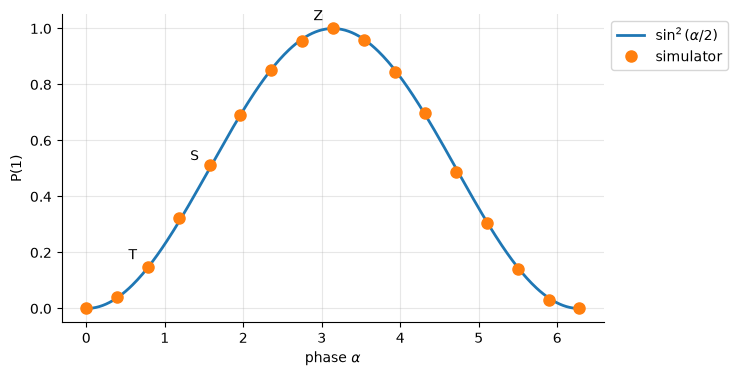

In [4]:
def interferometer(alpha: float) -> QuantumCircuit:
    qc = QuantumCircuit(1, 1)
    qc.h(0)
    qc.p(alpha, 0)
    qc.h(0)
    qc.measure(0, 0)
    return qc


alphas = np.linspace(0, 2 * np.pi, 17)
measured = [run(interferometer(a)).get('1', 0) / shots for a in alphas]
fine = np.linspace(0, 2 * np.pi, 300)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(fine, np.sin(fine / 2)**2, linewidth=2, label=r'$\sin^2(\alpha/2)$')
ax.plot(alphas, measured, 'o', markersize=8, label='simulator')
for name, a in {'T': np.pi / 4, 'S': np.pi / 2, 'Z': np.pi}.items():
    ax.annotate(name, (a, np.sin(a / 2)**2), xytext=(-14, 6), textcoords='offset points')
ax.set_xlabel(r'phase $\alpha$')
ax.set_ylabel('P(1)')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
ax.grid(alpha=0.3)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.show()

### 1.2 What one run can tell

One measurement gives one bit. It is certain only for $\alpha = 0$ (always 0) and $\alpha = \pi$ (always 1), when the factor
$e^{i\alpha}$ is $+1$ or $-1$. This is exactly the Deutsch–Jozsa situation (03, 2.2): the oracle multiplies the amplitudes by $\pm1$
only, so a single run is enough. A general $\alpha$ has to be estimated from many runs.

### 1.3 Estimating a phase from statistics

Run the interferometer $N$ times, count the ones and invert $p = \sin^2(\alpha/2)$. The error of $\hat p$ is $\sqrt{p(1-p)/N}$, and
dividing it by the slope $|\mathrm{d}p/\mathrm{d}\alpha|$ gives

$$\Delta\alpha \approx \frac{1}{\sqrt N}$$

Getting $t$ bits of the phase therefore takes about $4^t$ runs. Each extra bit costs four times more, and this is the number
to beat. We only need the binomial distribution here, so no circuit is involved. (In optics the same limit is called the
*shot-noise limit*. The Mach–Zehnder interferometer in the textbook is this circuit with a beam splitter for each $H$.)

<details>
<summary>Where the 1/√N comes from</summary>

**Noise in the measured probability.** Each run gives 1 with probability $p = \sin^2(\alpha/2)$. After $N$ runs the number of ones follows
a binomial distribution, so the estimate $\hat p$ has the standard deviation

$$\Delta p = \sqrt{\frac{p(1-p)}{N}}$$

**Converting to $\alpha$.** A small change of $\alpha$ shifts $p$ by about $|\mathrm{d}p/\mathrm{d}\alpha|\,\Delta\alpha$. Inverting that gives

$$\Delta\alpha \approx \frac{\Delta p}{|\mathrm{d}p/\mathrm{d}\alpha|}$$

A steep curve means a given error in $p$ matters little, a flat curve means it matters a lot.

**Plugging in $p$.** For $0 \le \alpha \le \pi$ both pieces turn out to be the same expression:

$$\sqrt{p(1-p)} = \sin\frac{\alpha}{2}\cos\frac{\alpha}{2},
\qquad \frac{\mathrm{d}p}{\mathrm{d}\alpha} = 2\sin\frac{\alpha}{2}\cos\frac{\alpha}{2}\cdot\frac12 = \sin\frac{\alpha}{2}\cos\frac{\alpha}{2}$$

They cancel, which leaves $\Delta\alpha \approx 1/\sqrt N$. The error does not depend on $\alpha$: where the curve is steep ($\alpha \approx \pi/2$), $p$ is also noisiest,
and near $\alpha = 0$ or $\pi$ the curve is flat but $p$ barely fluctuates.

**Example.** For $\alpha = 1$ and $N = 100$: $p \approx 0.230$, $\Delta p \approx 0.042$, the slope is $\frac12\sin 1 \approx 0.42$, so $\Delta\alpha \approx 0.1 = 1/\sqrt{100}$.

**Where $4^t$ comes from.** Knowing $t$ bits of the phase means an error of about $2^{-t}$, and $1/\sqrt N \approx 2^{-t}$ gives $N \approx 4^t$. This is a scaling
statement, not an exact count: $\alpha = 2\pi\varphi$ changes the prefactor, but not the factor of 4 per bit.

**Limits of the formula.**
* The second step is a linear approximation and it fails where the slope goes to zero. With $p$ almost 0 you may see no ones at all, which is why
the cell below uses $\alpha = 1$.
* $\alpha$ and $2\pi - \alpha$ give the same $p$, so this measurement only determines $\alpha$ within $[0, \pi]$. Telling them apart needs a second setting,
such as an extra $S$ gate before the last $H$.

</details>

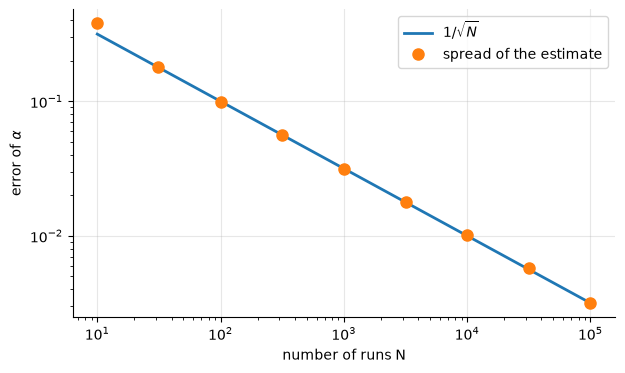

In [5]:
rng = np.random.default_rng()
alpha = 1.0                            # any value away from 0 and pi
runs = np.logspace(1, 5, 9).astype(int)

errors = []
for N_runs in runs:
    p_hat = rng.binomial(N_runs, np.sin(alpha / 2)**2, size=2000) / N_runs
    errors.append(np.std(2 * np.arcsin(np.sqrt(p_hat))))

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(runs, 1 / np.sqrt(runs), linewidth=2, label=r'$1/\sqrt{N}$')
ax.loglog(runs, errors, 'o', markersize=8, label='spread of the estimate')
ax.set_xlabel('number of runs N')
ax.set_ylabel(r'error of $\alpha$')
ax.legend()
ax.grid(alpha=0.3)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.show()

## 2. Phase kickback in general

### 2.1 Controlled operation on an eigenstate

So far kickback meant one thing: the oracle plus an output qubit in $|-\rangle$ gives a sign $\pm1$ (03, 2.2 and 04, 1.2). The reason is
not specific to oracles. The oracle is a controlled operation, $U_f = \sum_x |x\rangle\langle x| \otimes X^{f(x)}$, and $|-\rangle$
is an eigenstate of $X$ with eigenvalue $-1$.

The same happens for any unitary $U$ with an eigenstate $U|u\rangle = e^{2\pi i\varphi}|u\rangle$. For a controlled $U$:

$$\frac{|0\rangle + |1\rangle}{\sqrt2}\,|u\rangle \;\longmapsto\;
\frac{|0\rangle|u\rangle + |1\rangle U|u\rangle}{\sqrt2} =
\frac{|0\rangle + e^{2\pi i\varphi}|1\rangle}{\sqrt2}\,|u\rangle$$

On $|u\rangle$ alone the eigenvalue would be an unobservable global phase. On the control qubit it became a *relative* phase.

**Your turn.** Take $U = P(\alpha)$, whose eigenstates are $|0\rangle$ (eigenvalue 1) and $|1\rangle$ (eigenvalue $e^{i\alpha}$). Put $q_0$ into
$|+\rangle$, $q_1$ into $|1\rangle$, apply `qc.cp(alpha, 0, 1)` and look at both qubits with `plot_bloch_multivector`. Which qubit has moved,
the "target" or the "control"? What changes for $q_1$ in $|0\rangle$? Then add $H$ on $q_0$ and measure it: you have the interferometer from 1.1 again,
this time with the phase coming from a controlled gate.

In [14]:
alpha = np.pi / 2

# qc = QuantumCircuit(2)
# ...
# plot_bloch_multivector(Statevector(qc))




<details>
<summary>Solution</summary>

```python
alpha = np.pi / 2

qc = QuantumCircuit(2)
qc.h(0)
qc.x(1)                                # remove this line: q_1 in |0>, nothing moves
qc.cp(alpha, 0, 1)
display(plot_bloch_multivector(Statevector(qc)))

qc.h(0)
qc.measure_all()
print(run(qc))                         # q_1 is the left bit of the key
```

</details>

With $\alpha = 2\pi\varphi$ the probability from 1.1 reads $P(1) = \sin^2(\pi\varphi)$. Here it is for a few phases and for both eigenstates of $P$:

In [21]:
def kickback_interferometer(phi: float, target_one: bool) -> QuantumCircuit:
    qc = QuantumCircuit(2, 1)
    qc.h(0)
    if target_one:
        qc.x(1)
    qc.cp(2 * np.pi * phi, 0, 1)
    qc.h(0)
    qc.measure(0, 0)
    return qc


print('  phi | P(1), target |1> | sin^2(pi phi) | P(1), target |0>')
for phi in [1 / 8, 1 / 4, 1 / 3, 1 / 2]:
    p_one = run(kickback_interferometer(phi, True)).get('1', 0) / shots
    p_zero = run(kickback_interferometer(phi, False)).get('1', 0) / shots
    print(f'{phi:.3f} | {p_one:16.3f} | {np.sin(np.pi * phi)**2:13.3f} | {p_zero:16.3f}')

  phi | P(1), target |1> | sin^2(pi phi) | P(1), target |0>
0.125 |            0.141 |         0.146 |            0.000
0.250 |            0.499 |         0.500 |            0.000
0.333 |            0.745 |         0.750 |            0.000
0.500 |            1.000 |         1.000 |            0.000


### 2.2 The target outside an eigenstate - SKIP

The derivation needed an eigenstate. If the target is a superposition of eigenstates with *different* eigenvalues, each part
kicks a different phase back and the two registers become entangled. CNOT on $|+\rangle|0\rangle$ is the example you know: $|0\rangle = (|+\rangle + |-\rangle)/\sqrt2$ on the target
gives a Bell state, whereas $|+\rangle|-\rangle$ gives clean kickback (02, 1.6).

**Your turn.** Repeat 2.1 with $q_1$ in $|+\rangle$, a superposition of both eigenstates of $P(\alpha)$. Is the control qubit still in a pure state? Trace out $q_1$ with
`partial_trace(Statevector(qc), [1])` and call `.purity()` on the result (02, 1.7). Compare with the target in $|1\rangle$.

In [21]:
alpha = np.pi / 2

# qc = QuantumCircuit(2)
# ...
# rho_control = partial_trace(Statevector(qc), [1])
# print(rho_control.purity().real)


<details>
<summary>Solution</summary>

```python
alpha = np.pi / 2

qc = QuantumCircuit(2)
qc.h(0)
qc.h(1)                                # target in |+>; qc.x(1) instead gives purity 1
qc.cp(alpha, 0, 1)

rho_control = partial_trace(Statevector(qc), [1])
print(rho_control.purity().real)
```

</details>

For the target in $|+\rangle$ the purity of the control is $\frac12 + \frac12\cos^2\frac{\alpha}{2}$. The stronger the phase, the more entangled the two qubits, up to $\alpha = \pi$
(CZ on $|{+}{+}\rangle$), where the control alone is completely mixed and no interference is left to see.

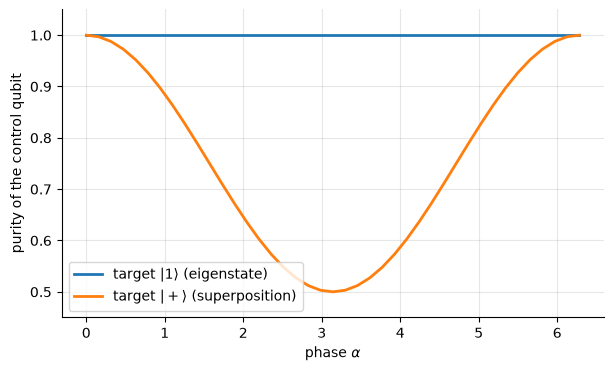

In [22]:
def control_purity(alpha: float, target_plus: bool) -> float:
    qc = QuantumCircuit(2)
    qc.h(0)
    if target_plus:
        qc.h(1)
    else:
        qc.x(1)
    qc.cp(alpha, 0, 1)
    return partial_trace(Statevector(qc), [1]).purity().real


alphas = np.linspace(0, 2 * np.pi, 41)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(alphas, [control_purity(a, False) for a in alphas], linewidth=2, label=r'target $|1\rangle$ (eigenstate)')
ax.plot(alphas, [control_purity(a, True) for a in alphas], linewidth=2, label=r'target $|+\rangle$ (superposition)')
ax.set_ylim(0.45, 1.05)
ax.set_xlabel(r'phase $\alpha$')
ax.set_ylabel('purity of the control qubit')
ax.legend()
ax.grid(alpha=0.3)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.show()

### 2.3 Who is the control? - SKIP

It looks odd that the *control* qubit is the one that changes. But "control" and "target" describe what a gate does to the computational
basis, they are not properties of the gate. $C(P(\alpha)) = \mathrm{diag}(1, 1, 1, e^{i\alpha})$ only touches $|11\rangle$, so it does not care which qubit we call which.
For CNOT the same symmetry hides in the choice of basis: in the basis $\{|+\rangle, |-\rangle\}$ the roles are swapped.

**Your turn.** Check both statements with `Operator`: (a) `cp(alpha, 0, 1)` and `cp(alpha, 1, 0)` are the same matrix, (b) CNOT with $H$ on both qubits before and after is
a CNOT with control and target swapped. Compare two circuits with `Operator(qc_a) == Operator(qc_b)`.

In [16]:
# qc_a = QuantumCircuit(2)
# ...
# qc_b = QuantumCircuit(2)
# ...
# print(Operator(qc_a) == Operator(qc_b))



<details>
<summary>Solution</summary>

```python
qc_a = QuantumCircuit(2)
qc_a.cp(1.0, 0, 1)
qc_b = QuantumCircuit(2)
qc_b.cp(1.0, 1, 0)
print(Operator(qc_a) == Operator(qc_b))

qc_a = QuantumCircuit(2)
qc_a.h([0, 1])
qc_a.cx(0, 1)
qc_a.h([0, 1])
qc_b = QuantumCircuit(2)
qc_b.cx(1, 0)
print(Operator(qc_a) == Operator(qc_b))
```

</details>

## 3. Controlled powers and the bits of a phase

### 3.1 Powers shift the binary point

From now on $U|u\rangle = e^{2\pi i\varphi}|u\rangle$ with a phase that has $t$ bits, $\varphi = 0.\varphi_1\varphi_2\dots\varphi_t$ in binary. The power $U^{2^k}$ has the same eigenstate,
with phase $2^k\varphi$. Multiplying by $2^k$ moves the binary point by $k$ places, and the integer part does not matter because $e^{2\pi i m} = 1$:

$$U^{2^k}|u\rangle = e^{2\pi i\,(0.\varphi_{k+1}\dots\varphi_t)}|u\rangle$$

So with the right power, the bit we want stands right behind the point:

In [ ]:
phi = Fraction(3, 8)                   # try Fraction(5, 16) with t = 4
t = 3

print(f'phi = {phi} = 0.{int(phi * 2**t):0{t}b} in binary')
for k in range(t):
    phase = (phi * 2**k) % 1
    print(f'U^{2**k}: phase {str(phase):>4} = 0.{int(phase * 2**t):0{t}b}')

phi = 3/8 = 0.011 in binary
U^1: phase  3/8 = 0.011
U^2: phase  3/4 = 0.110
U^4: phase  1/2 = 0.100


### 3.2 Reading the phase bit by bit

The highest power gives a phase $0.\varphi_t$, which is either $0$ or $\frac12$. That is $\alpha = 0$ or $\pi$ in the interferometer, so a single run reads the last bit with
certainty. The next power gives $0.\varphi_{t-1}\varphi_t$. We already know $\varphi_t$, so we can subtract its contribution with a phase gate before the last $H$, and again we
have $\alpha = 0$ or $\pi$. In this way we walk from the last bit to the first.

**Your turn.** Read $\varphi = 3/8 = 0.011_2$ yourself, with $U = P(2\pi\varphi)$ on a target in $|1\rangle$. Write a function `read_bit(k, correction)`: the interferometer from 2.1 with a
controlled $U^{2^k}$ and `qc.p(correction, 0)` before the last $H$. One shot is enough, use `run(qc, shots=1)`. Then read the three bits one after another, by hand:

- $k = 2$: no correction, gives $\varphi_3$
- $k = 1$: correction $-\frac{\pi}{2}\varphi_3$, gives $\varphi_2$
- $k = 0$: correction $-\frac{\pi}{2}\varphi_2 - \frac{\pi}{4}\varphi_3$, gives $\varphi_1$

In [28]:
phi = 3 / 8

# def read_bit(k, correction=0.0):
#     qc = QuantumCircuit(2, 1)
#     ...
#     counts = run(qc, shots=1)
#     return int(list(counts)[0])

    

<details>
<summary>Solution</summary>

```python
phi = 3 / 8


def read_bit(k, correction=0.0):
    qc = QuantumCircuit(2, 1)
    qc.x(1)
    qc.h(0)
    qc.cp(2 * np.pi * phi * 2**k, 0, 1)
    qc.p(correction, 0)
    qc.h(0)
    qc.measure(0, 0)
    counts = run(qc, shots=1)
    return int(list(counts)[0])


bit_3 = read_bit(2)
bit_2 = read_bit(1, -np.pi / 2 * bit_3)
bit_1 = read_bit(0, -np.pi / 2 * bit_2 - np.pi / 4 * bit_3)
print(f'phi = 0.{bit_1}{bit_2}{bit_3}')
```

</details>

You played the role of the classical computer: the correction depended on what you had already measured. Qiskit can do the same inside one circuit, with a measurement in the
middle, `reset` to reuse the qubit and `if_test` for the classical feedback. The classical bit $c_i$ holds bit $i$ of $y = 2^t\varphi$, least significant first.

The cost is $1 + 2 + \dots + 2^{t-1} = 2^t - 1$ applications of $U$, compared to the $4^t$ runs from 1.3.

expected 0101, got {'0101': 1000}


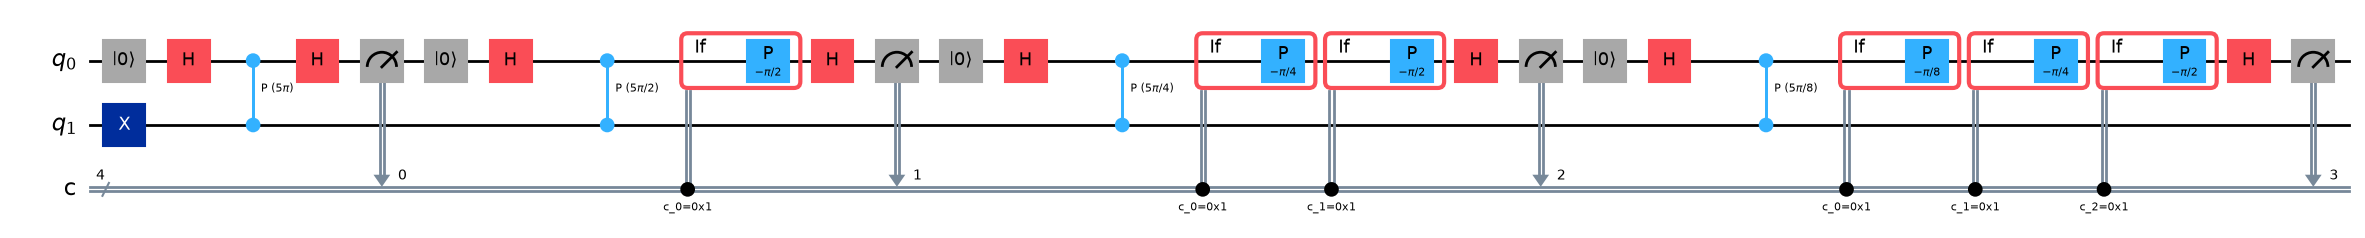

In [ ]:
def iterative_qpe(phi: float, t: int) -> QuantumCircuit:
    # One reused control qubit q_0, target q_1
    q, c = QuantumRegister(2, 'q'), ClassicalRegister(t, 'c')
    qc = QuantumCircuit(q, c)
    qc.x(1)
    for i in range(t):
        qc.reset(0)
        qc.h(0)
        qc.cp(2 * np.pi * phi * 2**(t - 1 - i), 0, 1)
        for j in range(i):
            with qc.if_test((c[j], 1)):
                qc.p(-np.pi / 2**(i - j), 0)
        qc.h(0)
        qc.measure(0, c[i])
    return qc


t = 4
phi = 5 / 16                           # try other multiples of 1/16, and something like 1/3
qc = iterative_qpe(phi, t)
print(f'expected {int(phi * 2**t):0{t}b}, got {run(qc, shots=1000)}')
qc.draw('mpl', fold=-1)

The same circuit, with each power written out the way a general $U$ needs it: $U^{2^k}$ is $2^k$ copies of the controlled $U$, all with the basic
angle $2\pi\varphi$. Count the copies, they are the $2^t - 1$ applications of $U$ from above. Compare the first block with the circuit above: eight copies
of $P(5\pi/8)$ do the same as one $P(5\pi)$.

expected 0101, got {'0101': 1000}
controlled U applied 15 times, 2^t - 1 = 15


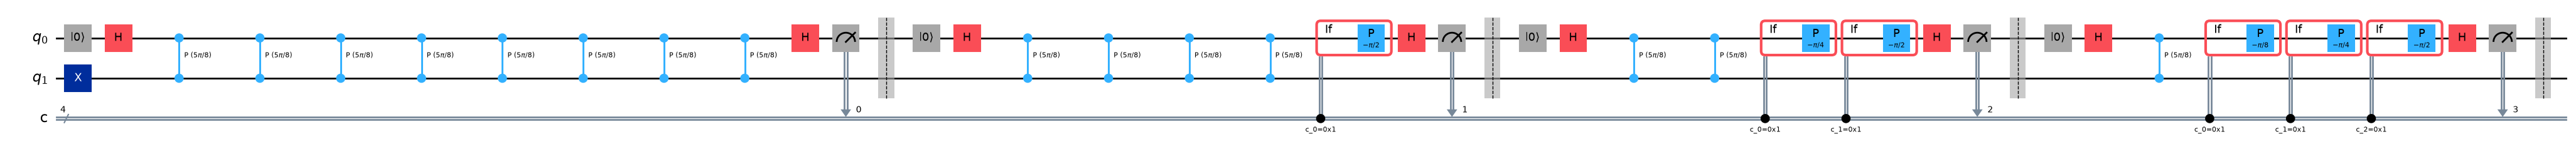

In [ ]:
def iterative_qpe_repeated(phi: float, t: int) -> QuantumCircuit:
    # As iterative_qpe, but U^(2^k) is applied as 2^k separate controlled U gates
    q, c = QuantumRegister(2, 'q'), ClassicalRegister(t, 'c')
    qc = QuantumCircuit(q, c)
    qc.x(1)
    for i in range(t):
        qc.reset(0)
        qc.h(0)
        for _ in range(2**(t - 1 - i)):
            qc.cp(2 * np.pi * phi, 0, 1)
        for j in range(i):
            with qc.if_test((c[j], 1)):
                qc.p(-np.pi / 2**(i - j), 0)
        qc.h(0)
        qc.measure(0, c[i])
        qc.barrier()
    return qc


qc = iterative_qpe_repeated(phi, t)
print(f'expected {int(phi * 2**t):0{t}b}, got {run(qc, shots=1000)}')
print(f'controlled U applied {qc.count_ops()["cp"]} times, 2^t - 1 = {2**t - 1}')
qc.draw('mpl', fold=-1)

### 3.3 All the bits at once

Instead of reusing one control qubit we can take $t$ of them: $q_k$ controls $U^{2^k}$, all at the same time, and nothing is measured. Each qubit picks up its own shifted phase, so
$q_0$ gets $\varphi$, $q_1$ gets $2\varphi$ and so on.

**Your turn.** Build it for $t = 3$ and $\varphi = 3/8$: $X$ on the target $q_3$, $H$ on $q_0, q_1, q_2$, and `cp` with the right angle from each $q_k$. No measurement. Look at
the state with `plot_bloch_multivector`. Do the angles on the equator match the table in 3.1?

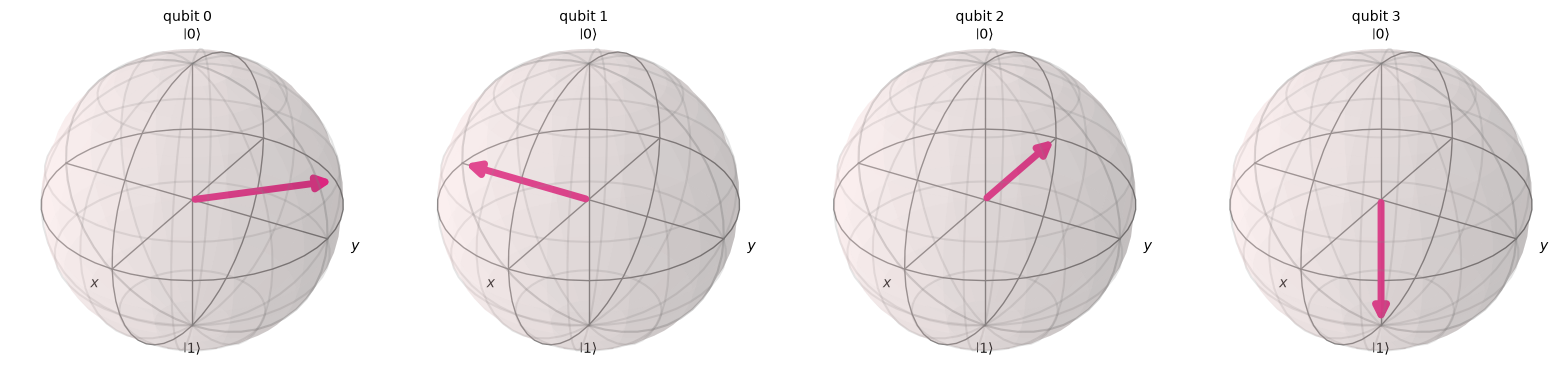

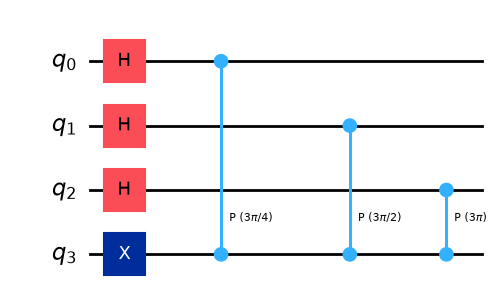

In [34]:
t = 3
phi = 3 / 8

# qc = QuantumCircuit(t + 1)
# ...
# plot_bloch_multivector(Statevector(qc))
t = 3
phi = 3 / 8

qc = QuantumCircuit(t + 1)
qc.x(t)
qc.h(range(t))
for k in range(t):
    qc.cp(2 * np.pi * phi * 2**k, k, t)


display(plot_bloch_multivector(Statevector(qc)))
qc.draw('mpl', fold=-1)

<details>
<summary>Solution</summary>

```python
t = 3
phi = 3 / 8

qc = QuantumCircuit(t + 1)
qc.x(t)
qc.h(range(t))
for k in range(t):
    qc.cp(2 * np.pi * phi * 2**k, k, t)

plot_bloch_multivector(Statevector(qc))
```

</details>

The phase now sits in the register as a product state, with one angle per qubit. Measured directly this gives uniformly random bits. In 3.2 we extracted the angles
one at a time, with corrections based on measurements. We want one circuit that does the whole read-out coherently. That circuit is the inverse of the quantum Fourier transform.

## 4. Quantum Fourier transform

### 4.1 From the DFT to the QFT

The discrete Fourier transform of $(x_0, \dots, x_{N-1})$ is $y_k = \frac{1}{\sqrt N}\sum_j x_j\, e^{2\pi i jk/N}$: the coefficient $y_k$ says how much of the wave with
$k$ periods the sequence contains. The QFT does the same to the amplitudes of a state with $N = 2^n$:

$$\mathrm{QFT}_N|j\rangle = \frac{1}{\sqrt N}\sum_{k=0}^{N-1} e^{2\pi i jk/N}|k\rangle, \qquad
\mathrm{QFT}_N\sum_j x_j|j\rangle = \sum_k y_k|k\rangle$$

The inverse $\mathrm{QFT}_N^\dagger$ has the opposite sign in the exponent.

**Your turn.** Write the matrix $F$ with elements $F_{kj} = e^{2\pi i jk/N}/\sqrt N$ in NumPy. Check that (a) it is unitary, (b) for $N = 2$ it is the Hadamard gate, (c) on a random vector it gives
the same result as `np.fft.ifft(x, norm='ortho')` (NumPy has the opposite sign convention than we do, its *inverse* FFT is our QFT).

In [32]:
N = 4

# F = ...
# print(np.round(F, 3))



<details>
<summary>Solution</summary>

```python
N = 4

F = np.array([[np.exp(2j * np.pi * j * k / N) for j in range(N)] for k in range(N)]) / np.sqrt(N)
print(np.round(F, 3))

print('unitary:', np.allclose(F.conj().T @ F, np.eye(N)))
x = np.random.rand(N)
print('same as ifft:', np.allclose(F @ x, np.fft.ifft(x, norm='ortho')))
```

</details>

### 4.2 What the QFT looks like

Amplitudes are complex numbers, so a bar plot hides half of them. We draw each amplitude as a **wheel**: the size of the disc is $|a|$, the hand shows its phase, and the colour shows the
phase as well. All other plots of this section use the same wheels.

The matrix $\mathrm{QFT}_8$ as wheels: the first row and the first column do nothing, in column $j$ the hand moves by $j/8$ of a turn from row to row.
Column 1 turns once around while going down the matrix, column 2 twice, and so on.

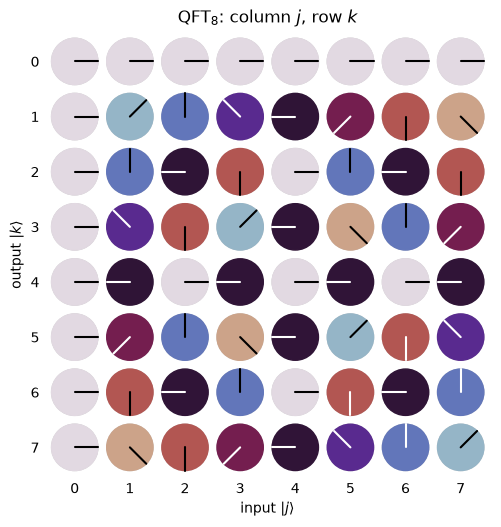

In [30]:
def qft_matrix(n: int) -> np.ndarray:
    N = 2**n
    return np.array([[np.exp(2j * np.pi * j * k / N) for j in range(N)] for k in range(N)]) / np.sqrt(N)


def plot_wheels(amps, row_labels=None, col_labels=None, title=None, ax=None):
    # One wheel per entry of a 2D array of amplitudes, sizes relative to the largest entry
    amps = np.atleast_2d(amps)
    rows, cols = amps.shape
    if ax is None:
        _, ax = plt.subplots(figsize=(0.6 * cols + 1, 0.6 * rows + 1))
    largest = np.abs(amps).max()
    for r in range(rows):
        for c in range(cols):
            a = amps[r, c] / largest * 0.42
            phase = np.angle(a) % (2 * np.pi)
            ax.add_patch(plt.Circle((c, -r), 0.42, fill=False, color='0.8', linewidth=1))
            if abs(a) > 1e-6:
                ax.add_patch(plt.Circle((c, -r), abs(a), color=plt.cm.twilight(phase / (2 * np.pi))))
                hand = 'white' if np.pi / 2 < phase < 3 * np.pi / 2 else 'black'
                ax.plot([c, c + a.real], [-r, -r + a.imag], color=hand, linewidth=1.5, solid_capstyle='round')
    ax.set_xlim(-0.55, cols - 0.45)
    ax.set_ylim(-rows + 0.45, 0.55)
    ax.set_aspect('equal')
    ax.set_xticks(range(cols), col_labels if col_labels is not None else [''] * cols)
    ax.set_yticks([-r for r in range(rows)], row_labels if row_labels is not None else [''] * rows)
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    if title:
        ax.set_title(title)
    return ax


n = 3
labels = [f'{x}' for x in range(2**n)]
ax = plot_wheels(qft_matrix(n), labels, labels, title=r'$\mathrm{QFT}_8$: column $j$, row $k$')
ax.set_xlabel(r'input $|j\rangle$')
ax.set_ylabel(r'output $|k\rangle$')
plt.show()

Each column of the matrix is a basis state of the *Fourier basis*: a complex wave with $j$ periods. Reading the amplitudes along $k$ as points in the complex plane gives a discrete helix, with
$j$ turns:

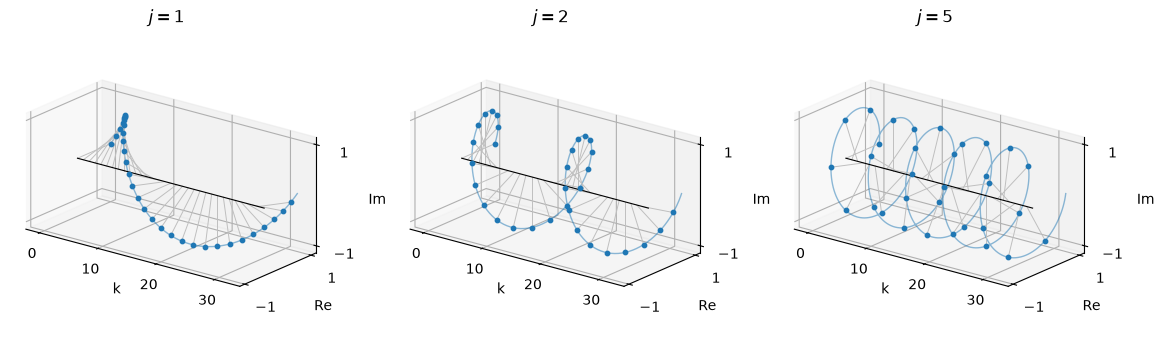

In [33]:
def plot_helices(frequencies: list[int], N: int = 32):
    fig = plt.figure(figsize=(3.9 * len(frequencies), 3.6))
    k_fine = np.linspace(0, N, 500)
    k = np.arange(N)
    for i, j in enumerate(frequencies, start=1):
        ax = fig.add_subplot(1, len(frequencies), i, projection='3d')
        ax.set_proj_type('ortho')
        ax.set_box_aspect((2.2, 1, 1))
        ax.view_init(elev=20, azim=-52)
        ax.plot(k_fine, np.cos(2 * np.pi * j * k_fine / N), np.sin(2 * np.pi * j * k_fine / N),
                color='tab:blue', linewidth=1, alpha=0.5)
        re, im = np.cos(2 * np.pi * j * k / N), np.sin(2 * np.pi * j * k / N)
        for x, y, z in zip(k, re, im):
            ax.plot([x, x], [0, y], [0, z], color='0.75', linewidth=0.7)
        ax.scatter(k, re, im, color='tab:blue', s=10, depthshade=False)
        ax.plot([0, N], [0, 0], [0, 0], color='k', linewidth=0.8)
        ax.set_title(rf'$j = {j}$')
        ax.set_xlabel('k')
        ax.set_ylabel('Re')
        ax.set_zlabel('Im')
        ax.set_yticks([-1, 1])
        ax.set_zticks([-1, 1])
    fig.subplots_adjust(left=0.01, right=0.96, bottom=0.05, top=0.92, wspace=0.12)
    plt.show()


plot_helices([1, 2, 5])

### 4.3 The circuit

The QFT is a product. Writing out the sum over $k$ bit by bit gives one factor per qubit, and in the Qiskit order (qubit $q_m$ has weight $2^m$):

$$\mathrm{QFT}_{2^n}|j\rangle = \frac{1}{2^{n/2}}\bigotimes_{m=n-1}^{0}\left(|0\rangle + e^{2\pi i\, 2^m j/2^n}|1\rangle\right)$$

This is the state from 3.3 with $\varphi = j/2^n$: $q_0$ has turned by $j/2^n$, $q_1$ by twice as much, and so on. To build it from $|j\rangle$:

1. $H$ on the top qubit $q_{n-1}$. It now holds $e^{i\pi j_{n-1}}$, the phase of its own bit.
2. Controlled phases from the lower qubits add the rest: `cp(pi/2)` from $q_{n-2}$, `cp(pi/4)` from $q_{n-3}$, ...
   Now the top qubit holds the phase $2\pi j/2^n$, the phase $q_0$ should have.
3. The same for $q_{n-2}$, without $q_{n-1}$, and so on down to $q_0$, which only gets an $H$.
4. The factors have come out in the reverse order, so swap the qubits.

**Your turn.** Build the QFT for $n = 3$, gate by gate, without a loop. Compare `Operator(qc).data` with `qft_matrix(3)` using `np.allclose`. If it does not fit, try $n = 2$ first:
`qc.h(1)`, `qc.cp(np.pi / 2, 0, 1)`, `qc.h(0)`, `qc.swap(0, 1)`. What goes wrong without the swap?

True


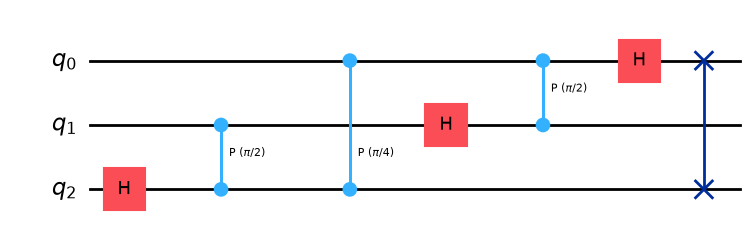

In [ ]:
# qc = QuantumCircuit(3)
# ...
# print(np.allclose(Operator(qc).data, qft_matrix(3)))
# qc.draw('mpl')


<details>
<summary>Solution</summary>

```python
qc = QuantumCircuit(3)
qc.h(2)
qc.cp(np.pi / 2, 1, 2)
qc.cp(np.pi / 4, 0, 2)
qc.h(1)
qc.cp(np.pi / 2, 0, 1)
qc.h(0)
qc.swap(0, 2)

print(np.allclose(Operator(qc).data, qft_matrix(3)))
qc.draw('mpl')
```

</details>

The same with loops, for any $n$. We use this function from now on. In Qiskit the gate is `QFTGate(n)`; older tutorials use the class `QFT`, which is deprecated since Qiskit 2.1.

n = 1: qft(n) == definition: True, QFTGate(n) == definition: True
n = 2: qft(n) == definition: True, QFTGate(n) == definition: True
n = 3: qft(n) == definition: True, QFTGate(n) == definition: True
n = 4: qft(n) == definition: True, QFTGate(n) == definition: True
n = 5: qft(n) == definition: True, QFTGate(n) == definition: True


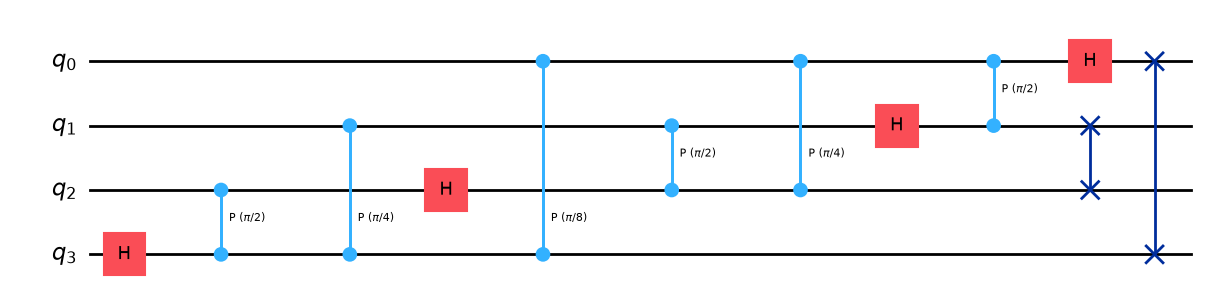

In [36]:
def qft(n: int) -> QuantumCircuit:
    qc = QuantumCircuit(n, name='QFT')
    for target in reversed(range(n)):
        qc.h(target)
        for control in reversed(range(target)):
            qc.cp(np.pi / 2**(target - control), control, target)
    for i in range(n // 2):
        qc.swap(i, n - i - 1)
    return qc


for n_ in range(1, 6):
    print(f'n = {n_}: qft(n) == definition: {np.allclose(Operator(qft(n_)).data, qft_matrix(n_))}, '
          f'QFTGate(n) == definition: {np.allclose(Operator(QFTGate(n_)).data, qft_matrix(n_))}')

qft(4).draw('mpl')

### 4.4 A change of basis

The Hadamard gate takes the computational basis to the $X$ basis, and the QFT, of which $H$ is the case $N = 2$, takes it to the *Fourier basis*. Measuring in the Fourier basis works the same way as measuring in the
$X$ basis (02, 4.2): rotate back, then measure.

**Your turn.** With as little code as possible, take a basis state $|j\rangle$ through the basis change: prepare $|5\rangle$ on 3 qubits with $X$ gates, apply `qft(3)`, and look at the amplitudes with
`plot_wheels(Statevector(qc).data)`. What do you get if you measure now? And if you apply `qft(3).inverse()` before the measurement?

In [39]:
n, j = 3, 5

# qc = QuantumCircuit(n)
# X gates on the qubits where j has a 1
# qc.compose(qft(n), inplace=True)
# plot_wheels(Statevector(qc).data)


<details>
<summary>Solution</summary>

```python
n, j = 3, 5

qc = QuantumCircuit(n)
for q in range(n):
    if (j >> q) & 1:
        qc.x(q)
qc.compose(qft(n), inplace=True)
plot_wheels(Statevector(qc).data, col_labels=range(2**n))
plt.show()

in_fourier_basis = qc.compose(qft(n).inverse())
qc.measure_all()
in_fourier_basis.measure_all()
print('measured directly:', run(qc))
print('after the inverse QFT:', run(in_fourier_basis))
```

</details>

All the amplitudes have the same size, so a direct measurement gives a uniformly random result and $j$ is invisible. It is hidden in the phases, in the same way as the phase of $|+\rangle$ versus $|-\rangle$.
The inverse QFT brings it back with certainty.

**Counting in two bases.** In the computational basis $j$ is written in bits (left, north or south pole of each qubit). In the Fourier basis it is written in angles on the
equator (right): every step of $j$ turns $q_0$ by $1/8$ of a turn, $q_1$ by $1/4$ and $q_2$ by $1/2$. The Fourier basis has its own positional number system. The positions on the right are computed from the actual circuit, not from the formula:

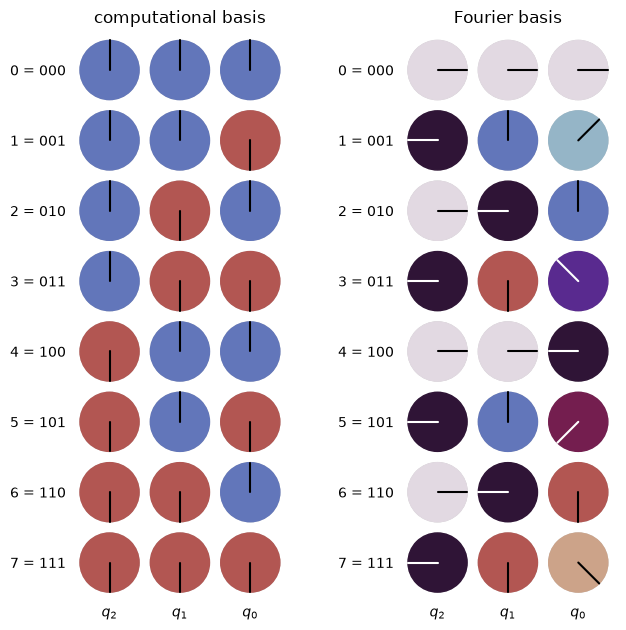

In [40]:
def bloch_positions(state: Statevector) -> np.ndarray:
    # x + iy of the Bloch vector of every qubit, for a product state on the equator this is e^{i angle}
    n = state.num_qubits
    positions = []
    for q in range(n):
        others = [other for other in range(n) if other != q]
        positions.append(2 * partial_trace(state, others).data[1, 0])
    return np.array(positions)


n = 3
bits, fourier = [], []
for j in range(2**n):
    qc = QuantumCircuit(n)
    for q in range(n):
        if (j >> q) & 1:
            qc.x(q)
    bits.append([-1j if (j >> q) & 1 else 1j for q in reversed(range(n))])   # hand up for 0, down for 1
    qc.compose(qft(n), inplace=True)
    fourier.append(bloch_positions(Statevector(qc))[::-1])

qubit_labels = [f'$q_{q}$' for q in reversed(range(n))]
state_labels = [f'{j} = {j:0{n}b}' for j in range(2**n)]
fig, (ax_bits, ax_fourier) = plt.subplots(1, 2, figsize=(7, 6.4))
plot_wheels(bits, state_labels, qubit_labels, title='computational basis', ax=ax_bits)
plot_wheels(fourier, state_labels, qubit_labels, title='Fourier basis', ax=ax_fourier)
plt.tight_layout()
plt.show()

**Your turn.** You do not need the QFT to get to the Fourier basis, the formula in 4.3 tells you directly what to do: $H$ on every qubit, then `qc.p(2 * np.pi * 2**m * j / 2**n, m)` on qubit $m$. Prepare the state for
$j = 5$ this way, apply the inverse QFT and measure. Then try a $j$ that is not an integer, such as $j = 5.5$. Which step of QPE have you just built?

In [ ]:
n, j = 3, 5

# qc = QuantumCircuit(n)
# ...
# qc.compose(qft(n).inverse(), inplace=True)
# qc.measure_all()
# print(run(qc))

<details>
<summary>Solution</summary>

```python
n, j = 3, 5                            # j = 5.5 gives a spread over the neighbours

qc = QuantumCircuit(n)
qc.h(range(n))
for m in range(n):
    qc.p(2 * np.pi * 2**m * j / 2**n, m)
qc.compose(qft(n).inverse(), inplace=True)
qc.measure_all()
print(run(qc))
```

</details>

### 4.5 A real Fourier transform

Since the QFT acts on amplitudes, a signal stored in the amplitudes gets a true Fourier transform, and the measurement samples its spectrum.

**Your turn.** Take the signal from the textbook on $N = 32$ points: $x_j = \cos(2\pi\cdot 2j/N) + \frac12\cos(2\pi\cdot 5j/N)$. Load it with `qc.initialize(x / np.linalg.norm(x), range(5))`, apply `qft(5)`,
measure and plot the histogram. Which $k$ show up and why are there four of them? What is the ratio of their probabilities? Then invent a signal of your own: more waves, other frequencies, a square wave.

In [ ]:
n = 5
N = 2**n
j = np.arange(N)
x = np.cos(2 * np.pi * 2 * j / N) + 0.5 * np.cos(2 * np.pi * 5 * j / N)

# qc = QuantumCircuit(n)
# ...

<details>
<summary>Solution</summary>

```python
n = 5
N = 2**n
j = np.arange(N)
x = np.cos(2 * np.pi * 2 * j / N) + 0.5 * np.cos(2 * np.pi * 5 * j / N)

qc = QuantumCircuit(n)
qc.initialize(x / np.linalg.norm(x), range(n))
qc.compose(qft(n), inplace=True)
qc.measure_all()

counts = run(qc)
print({int(key, 2): value for key, value in sorted(counts.items(), key=lambda item: int(item[0], 2))})
```

</details>

The peaks are at $k = 2$ and $k = 5$, the numbers of periods of the two waves, with amplitudes $2:1$ and so probabilities $4:1$. A real signal has a mirror image at $N - k$, since a cosine is a sum of two complex waves with opposite frequencies. All of it from 4096 shots of a 5-qubit circuit:

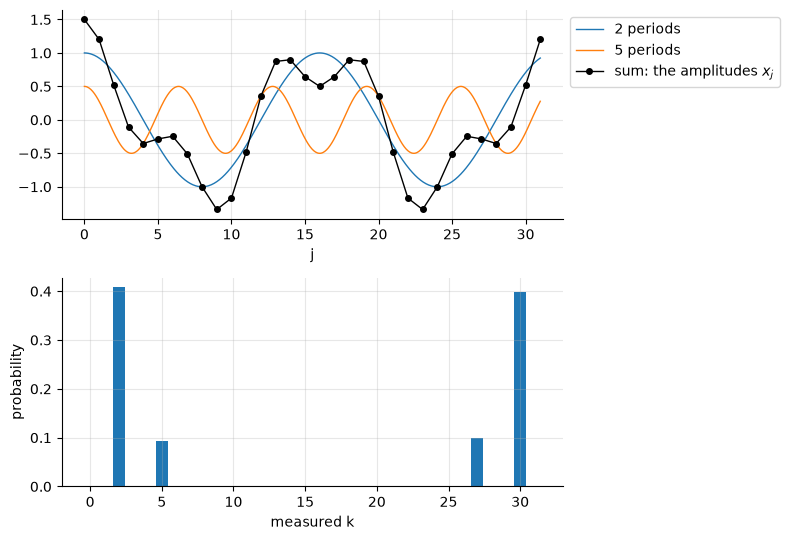

In [ ]:
def sampled_spectrum(x: np.ndarray) -> np.ndarray:
    n = int(np.log2(len(x)))
    qc = QuantumCircuit(n)
    qc.initialize(x / np.linalg.norm(x), range(n))
    qc.compose(qft(n), inplace=True)
    qc.measure_all()
    counts = run(qc)
    return np.array([counts.get(f'{k:0{n}b}', 0) / shots for k in range(2**n)])


N = 32
j = np.arange(N)
j_fine = np.linspace(0, N - 1, 500)
wave_1 = lambda z: np.cos(2 * np.pi * 2 * z / N)
wave_2 = lambda z: 0.5 * np.cos(2 * np.pi * 5 * z / N)
spectrum = sampled_spectrum(wave_1(j) + wave_2(j))

fig, (ax_signal, ax_spectrum) = plt.subplots(2, 1, figsize=(8, 5.5))
ax_signal.plot(j_fine, wave_1(j_fine), linewidth=1, label='2 periods')
ax_signal.plot(j_fine, wave_2(j_fine), linewidth=1, label='5 periods')
ax_signal.plot(j, wave_1(j) + wave_2(j), 'o-', color='k', markersize=4, linewidth=1, label='sum: the amplitudes $x_j$')
ax_signal.set_xlabel('j')
ax_signal.legend(loc='upper left', bbox_to_anchor=(1, 1))
ax_spectrum.bar(range(N), spectrum)
ax_spectrum.set_xlabel('measured k')
ax_spectrum.set_ylabel('probability')
for ax in (ax_signal, ax_spectrum):
    ax.grid(alpha=0.3)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

**This is not a faster FFT.** The state contains all 32 Fourier coefficients, but a measurement gives only one sample of $k$, with probability $|y_k|^2$. The phases of the coefficients are lost. And loading $N$ arbitrary numbers into amplitudes
is expensive by itself. The QFT is useful when we only need a global property of the state, such as a period.

**Periods.** A state with a period $r$ in a register of size $Q$ has peaks at the multiples of $Q/r$ after the QFT. A shift of the state changes only the phases, the probabilities stay the same. If $Q/r$ is not an integer, the peaks
get smeared around the nearest integers. This picture returns in Shor's algorithm.

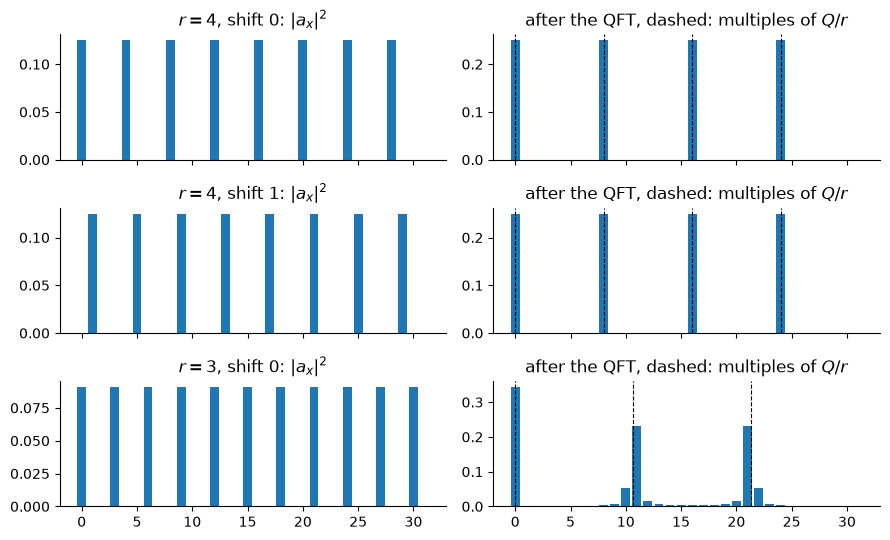

In [ ]:
def periodic_state(Q: int, r: int, shift: int = 0) -> np.ndarray:
    a = np.zeros(Q)
    a[shift::r] = 1
    return a / np.linalg.norm(a)


Q = 32
fig, axes = plt.subplots(3, 2, figsize=(9, 5.5), sharex=True)
for row, (r, shift) in zip(axes, [(4, 0), (4, 1), (3, 0)]):
    a = periodic_state(Q, r, shift)
    row[0].bar(range(Q), a**2)
    row[0].set_title(rf'$r = {r}$, shift {shift}: $|a_x|^2$')
    row[1].bar(range(Q), np.abs(qft_matrix(5) @ a)**2)
    row[1].set_title(r'after the QFT, dashed: multiples of $Q/r$')
    for s in range(r):
        row[1].axvline(s * Q / r, color='k', linestyle='--', linewidth=0.8)
    for ax in row:
        for side in ('top', 'right'):
            ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

### 4.6 Cost and the approximate QFT

The QFT uses $n$ Hadamards, $n(n-1)/2$ controlled phases and $\lfloor n/2\rfloor$ swaps, so $O(n^2)$ gates, against the $O(N\log N)$ operations of the classical FFT on $N = 2^n$ numbers. But most of the
rotations are tiny: the angle halves with every step away from the target, and on a real device $\pi/2^{10}$ is below the error of the gate that implements it. They can be left out.

**Your turn.** Copy `qft` and call it `approximate_qft(n, m)`: keep only the rotations with `target - control <= m`. For $n = 8$, how many `cp` gates are left for $m = 2, 3, 4$? How close is it to the exact QFT? A measure of the distance
of two unitaries $A, B$ is the overlap $|\mathrm{Tr}(A^\dagger B)|/N$, which is 1 for equal matrices.

In [ ]:
# def approximate_qft(n: int, m: int) -> QuantumCircuit:
#     ...

<details>
<summary>Solution</summary>

```python
def approximate_qft(n: int, m: int) -> QuantumCircuit:
    qc = QuantumCircuit(n, name='AQFT')
    for target in reversed(range(n)):
        qc.h(target)
        for control in reversed(range(target)):
            if target - control <= m:
                qc.cp(np.pi / 2**(target - control), control, target)
    for i in range(n // 2):
        qc.swap(i, n - i - 1)
    return qc


exact = Operator(qft(8)).data
for m in [2, 3, 4]:
    approx = approximate_qft(8, m)
    overlap = abs(np.trace(exact.conj().T @ Operator(approx).data)) / 2**8
    print(f'm = {m}: {approx.count_ops()["cp"]} cp gates, overlap {overlap:.4f}')
```

</details>

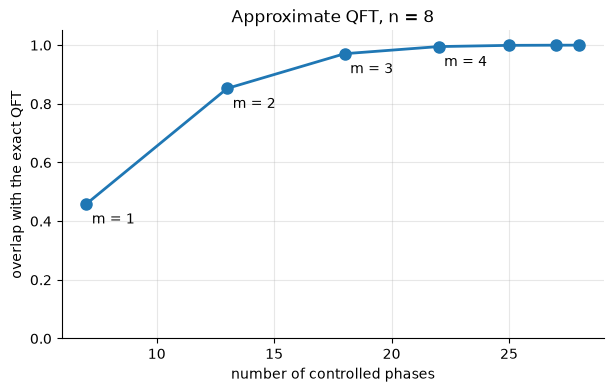

In [ ]:
def qft_truncated(n: int, m: int) -> QuantumCircuit:
    qc = QuantumCircuit(n)
    for target in reversed(range(n)):
        qc.h(target)
        for control in reversed(range(target)):
            if target - control <= m:
                qc.cp(np.pi / 2**(target - control), control, target)
    for i in range(n // 2):
        qc.swap(i, n - i - 1)
    return qc


n = 8
exact = Operator(qft(n)).data
ms = range(1, n)
gates = [qft_truncated(n, m).count_ops().get('cp', 0) for m in ms]
overlaps = [abs(np.trace(exact.conj().T @ Operator(qft_truncated(n, m)).data)) / 2**n for m in ms]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(gates, overlaps, marker='o', markersize=8, linewidth=2)
for g, o, m in list(zip(gates, overlaps, ms))[:4]:
    ax.annotate(f'm = {m}', (g, o), xytext=(4, -14), textcoords='offset points')
ax.set_ylim(0, 1.05)
ax.set_xlabel('number of controlled phases')
ax.set_ylabel('overlap with the exact QFT')
ax.set_title(f'Approximate QFT, n = {n}')
ax.grid(alpha=0.3)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.show()

## 5. Quantum phase estimation

### 5.1 Putting it together

**Input:** a circuit for $U$ and its eigenstate $|u\rangle$, $U|u\rangle = e^{2\pi i\varphi}|u\rangle$, $0 \le \varphi < 1$.

**Output:** a $t$-bit number $y$ with $y/2^t \approx \varphi$.

You have all the pieces: the $H$ gates and controlled powers from 3.3 write $\varphi$ into the angles of the register, which is the Fourier state from 4.4, and the inverse QFT turns it into the bits of $\varphi$.

$$\frac{1}{\sqrt{T}}\sum_{x=0}^{T-1}|x\rangle|u\rangle \;\longmapsto\;
\frac{1}{\sqrt{T}}\sum_{x=0}^{T-1} e^{2\pi i\varphi x}|x\rangle|u\rangle \;\xrightarrow{\;\mathrm{QFT}^\dagger\;}\; \sum_y a_y|y\rangle|u\rangle,
\qquad T = 2^t$$

If $\varphi = m/T$ for an integer $m$, the sum gives $a_m = 1$ and we measure $m$ with certainty.

**Your turn.** Build QPE for the $T$ gate with $t = 3$ control qubits, in 4 qubits and 5 steps:

1. target $q_3$ in the eigenstate $|1\rangle$
2. $H$ on $q_0, q_1, q_2$
3. $q_k$ controls $T^{2^k}$: repeat `qc.cp(np.pi / 4, k, 3)` $2^k$ times
4. `qc.compose(qft(3).inverse(), range(3), inplace=True)`
5. measure $q_0, q_1, q_2$

Which $\varphi$ do you get? Then try $S$ (`np.pi / 2`), $Z$ (`np.pi`), and the target in $|0\rangle$.

In [ ]:
t = 3

# qc = QuantumCircuit(t + 1, t)
# ...
# counts = run(qc)

<details>
<summary>Solution</summary>

```python
t = 3

qc = QuantumCircuit(t + 1, t)
qc.x(t)
qc.h(range(t))
for k in range(t):
    for _ in range(2**k):
        qc.cp(np.pi / 4, k, t)
qc.compose(qft(t).inverse(), range(t), inplace=True)
qc.measure(range(t), range(t))

counts = run(qc)
y = int(max(counts, key=counts.get), 2)
print(counts, f'phi = {y} / {2**t} = {y / 2**t}')
```

</details>

**Reading the result.** With $q_k$ controlling $U^{2^k}$, the qubit $q_k$ has weight $2^k$ and the key `'001'` is simply $y = 1$, so $\varphi = 1/8$. Do **not** reverse the string, that would give $4/8$. The textbook draws the most significant qubit on top, Qiskit draws $q_0$ on top, so the
two pictures are mirror images of each other.

### 5.2 QPE for any matrix

For a general version we take $U$ as a NumPy matrix. `UnitaryGate(...).control(1)` makes a controlled gate of any matrix, and `prepare` is a small circuit that puts the system register into the state we want.

This uses `matrix_power` to get $U^{2^k}$, which works because a small matrix is cheap for us. On a quantum computer the power is the expensive part (5.5).

{'01': 4096}


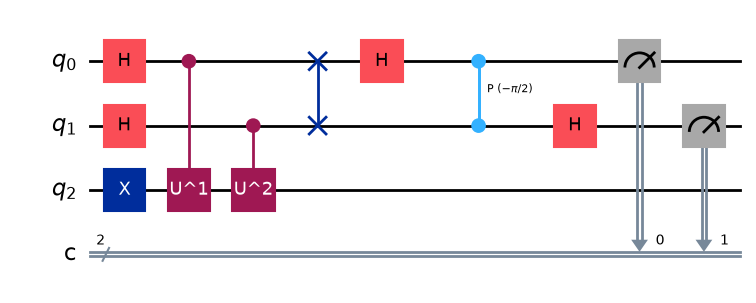

In [ ]:
def qpe(U: np.ndarray, t: int, prepare: QuantumCircuit, measure: bool = True) -> QuantumCircuit:
    # Control register q_0 ... q_{t-1}, q_k controls U^(2^k); the system is on the remaining qubits
    n = prepare.num_qubits
    system = list(range(t, t + n))
    qc = QuantumCircuit(t + n, t)
    qc.compose(prepare, system, inplace=True)
    qc.h(range(t))
    for k in range(t):
        power = UnitaryGate(np.linalg.matrix_power(U, 2**k), label=f'U^{2**k}').control(1)
        qc.append(power, [k] + system)
    qc.compose(qft(t).inverse(), range(t), inplace=True)
    if measure:
        qc.measure(range(t), range(t))
    return qc


S = np.array([[1, 0], [0, 1j]])
one = QuantumCircuit(1)
one.x(0)

qc = qpe(S, 2, one)                    # phi = 1/4 = 0.01 in binary
print(run(qc))
qc.draw('mpl', fold=-1)

**Your turn.** Estimate the eigenvalues of a matrix you know. A real rotation by $\theta$ is not diagonal, and its eigenvalues are $e^{\pm i\theta}$. Take $\theta = 2\pi\cdot\frac{3}{16}$ and $t = 4$. First prepare one eigenvector (from
`np.linalg.eig`, with `prepare.initialize(vector, 0)`), then the other one, then simply $|0\rangle$. What does the last case give? Compare with $\varphi$ computed by NumPy. Other matrices worth trying: $X$, $H$, $\frac{1}{\sqrt 2}(X + Y)$.

In [ ]:
theta = 2 * np.pi * 3 / 16
U = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
eigenvalues, vectors = np.linalg.eig(U)
print('phases from NumPy:', np.angle(eigenvalues) / (2 * np.pi) % 1)

# prepare = QuantumCircuit(1)
# prepare.initialize(vectors[:, 0], 0)
# print(run(qpe(U, 4, prepare)))

phases from NumPy: [0.1875 0.8125]


<details>
<summary>Solution</summary>

```python
theta = 2 * np.pi * 3 / 16
U = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
eigenvalues, vectors = np.linalg.eig(U)
print('phases from NumPy:', np.angle(eigenvalues) / (2 * np.pi) % 1)

for i in range(2):
    prepare = QuantumCircuit(1)
    prepare.initialize(vectors[:, i], 0)
    print(f'eigenvector {i}:', run(qpe(U, 4, prepare)))

print('|0>:', run(qpe(U, 4, QuantumCircuit(1))))    # both peaks, half of the shots each
```

</details>

**A spectrometer.** A state that is not an eigenstate gives all the eigenvalues it contains, each with the weight $|\langle u_j|\psi\rangle|^2$. So we can choose a spectrum, hide it in a random-looking matrix $U = V\,\mathrm{diag}(e^{2\pi i\varphi_j})\,V^\dagger$, and read it back. The matrix itself gives
nothing away, the histogram does. Choose your own `phases`, multiples of $1/2^t$ give sharp peaks.

[[-0.07-0.06j  0.47+0.41j -0.58+0.01j  0.28-0.43j]
 [ 0.63+0.26j  0.42+0.29j  0.08+0.18j -0.03+0.48j]
 [ 0.06-0.46j  0.14+0.02j -0.31-0.41j -0.67+0.21j]
 [ 0.14-0.54j -0.38+0.43j  0.05+0.59j -0.09-0.06j]]


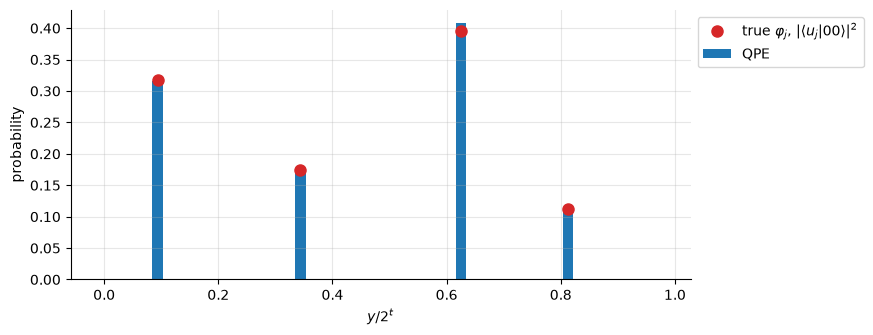

In [ ]:
t = 5
phases = np.array([3, 11, 20, 26]) / 2**t   # try your own, any four multiples of 1/32

V = random_unitary(4, seed=7).data
U = V @ np.diag(np.exp(2j * np.pi * phases)) @ V.conj().T
print(np.round(U, 2))

counts = run(qpe(U, t, QuantumCircuit(2)))  # start from |00>
measured = np.array([counts.get(f'{y:0{t}b}', 0) / shots for y in range(2**t)])
weights = np.abs(V.conj().T[:, 0])**2       # |<u_j|00>|^2

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(np.arange(2**t) / 2**t, measured, width=0.6 / 2**t, label='QPE')
ax.plot(phases, weights, 'o', color='tab:red', markersize=8, label=r'true $\varphi_j$, $|\langle u_j|00\rangle|^2$')
ax.set_xlabel(r'$y / 2^t$')
ax.set_ylabel('probability')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
ax.grid(alpha=0.3)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.show()

### 5.3 A phase that does not fit into $t$ bits

If $T\varphi$ is not an integer, no single $y$ is correct. The amplitudes are the geometric sum

$$a_y = \frac{1}{T}\sum_{x=0}^{T-1} e^{2\pi i x(\varphi - y/T)}$$

and the probability concentrates around the nearest integers to $T\varphi$.

**Your turn.** Take $\varphi = 1/3$ with $U = P(2\pi/3)$ and $|1\rangle$ on the system (`one` from 5.2), and use `qpe` for $t = 3, 5, 8$. What is the most frequent $y/2^t$ and how far is it from $1/3$? Then try $\varphi = 3/8$, which $t = 3$ gets exactly.

In [ ]:
phi = 1 / 3
U = np.diag([1, np.exp(2j * np.pi * phi)])

# for t in [3, 5, 8]:
#     ...

<details>
<summary>Solution</summary>

```python
phi = 1 / 3
U = np.diag([1, np.exp(2j * np.pi * phi)])

for t in [3, 5, 8]:
    counts = run(qpe(U, t, one))
    y = int(max(counts, key=counts.get), 2)
    print(f't = {t}: y = {y}, y / 2^t = {y / 2**t:.4f}, P = {counts[f"{y:0{t}b}"] / shots:.3f}')
```

</details>

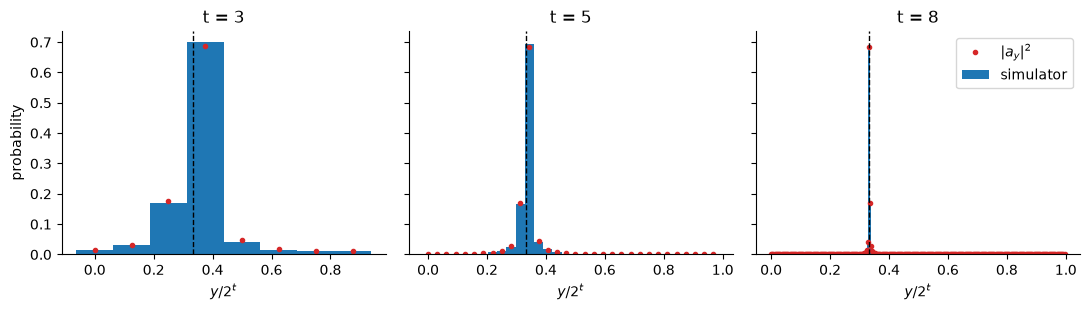

In [ ]:
def qpe_probabilities(phi: float, t: int) -> np.ndarray:
    # |a_y|^2 from the formula above
    T = 2**t
    a = np.exp(2j * np.pi * np.outer(phi - np.arange(T) / T, np.arange(T))).sum(axis=1) / T
    return np.abs(a)**2


phi = 1 / 3
U = np.diag([1, np.exp(2j * np.pi * phi)])

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, t in zip(axes, [3, 5, 8]):
    counts = run(qpe(U, t, one))
    ys = np.arange(2**t) / 2**t
    ax.bar(ys, [counts.get(f'{y:0{t}b}', 0) / shots for y in range(2**t)], width=1 / 2**t, label='simulator')
    ax.plot(ys, qpe_probabilities(phi, t), 'o', color='tab:red', markersize=3, label=r'$|a_y|^2$')
    ax.axvline(phi, color='k', linestyle='--', linewidth=1)
    ax.set_title(f't = {t}')
    ax.set_xlabel(r'$y / 2^t$')
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel('probability')
axes[-1].legend()
plt.tight_layout()
plt.show()

The same formula for *every* phase at once: each column of this picture is a histogram for one $\varphi$. The staircase is the $t$-bit read-out. On a step the peak is a single $y$, between two steps the probability is split among the neighbours. The worst case
sits right in the middle of a step, and even there the nearest $y$ has probability above $4/\pi^2 \approx 0.405$.

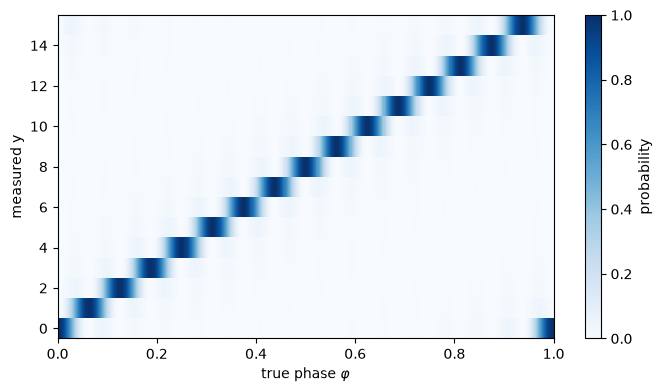

smallest P(most likely y) over all phases: 0.407


In [ ]:
t = 4
phis = np.linspace(0, 1, 481)
response = np.array([qpe_probabilities(phi, t) for phi in phis]).T

fig, ax = plt.subplots(figsize=(8, 4.2))
image = ax.imshow(response, origin='lower', aspect='auto', cmap='Blues', interpolation='nearest',
                  extent=[0, 1, -0.5, 2**t - 0.5])
ax.set_xlabel(r'true phase $\varphi$')
ax.set_ylabel('measured y')
fig.colorbar(image, label='probability')
plt.show()

print(f'smallest P(most likely y) over all phases: {response.max(axis=0).min():.3f}')

**Counting in the Fourier basis, animated.** Left: the $t$ qubits of the control register, each as a wheel, after the controlled powers. $q_0$ goes once around while $\varphi$ goes from 0 to 1, $q_3$ goes around 8 times. It is the number system from 4.4, run
continuously. Right: the distribution of $y$ after the inverse QFT. When $\varphi$ is a multiple of $1/16$ it is one bar. (The animation does not play on GitHub, the static picture above shows the same. The cell runs for a few seconds.)

In [ ]:
def qpe_animation(t: int = 4, frames: int = 96):
    fig, (ax_wheels, ax_bars) = plt.subplots(1, 2, figsize=(8.6, 2.9), dpi=70, width_ratios=[1, 1.15])
    ys = np.arange(2**t)
    qubit_labels = [f'$q_{k}$' for k in reversed(range(t))]

    def draw(frame):
        phi = frame / frames
        ax_wheels.clear()
        ax_bars.clear()
        plot_wheels([np.exp(2j * np.pi * phi * 2**k) for k in reversed(range(t))], col_labels=qubit_labels,
                    title=rf'$\varphi$ = {phi:.3f}', ax=ax_wheels)
        ax_bars.bar(ys, qpe_probabilities(phi, t), color='tab:blue')
        ax_bars.set_ylim(0, 1.05)
        ax_bars.set_xlabel('measured y')
        ax_bars.set_ylabel('probability')
        for side in ('top', 'right'):
            ax_bars.spines[side].set_visible(False)
        fig.tight_layout()

    animation = FuncAnimation(fig, draw, frames=frames, interval=120)
    html = animation.to_jshtml(default_mode='loop')
    plt.close(fig)
    return HTML(html)


qpe_animation()

### 5.4 The input is not an eigenstate

For $|\psi\rangle = \sum_j c_j|u_j\rangle$ linearity gives $\sum_j c_j|\tilde\varphi_j\rangle|u_j\rangle$: each eigenstate has its own estimate. So the control register and the system are entangled, and a measurement gives $\varphi_j$ with probability $|c_j|^2$ and leaves the system in (or near) $|u_j\rangle$.
This has two consequences: QPE does not return a list of all eigenvalues, one run gives one of them, and it also *prepares* the corresponding eigenstate.

A physical example is measuring energy. Take two spins with the Heisenberg interaction $H = XX + YY + ZZ$. Its eigenvalues are $E = +1$ (three triplet states) and $E = -3$ (the singlet). The time evolution $U = e^{iH\tau}$ has the phases $\varphi = E\tau/2\pi$, and for $\tau = \pi/4$ they
are exactly $\frac18$ and $-\frac38 \equiv \frac58$, so $t = 3$ is enough.

**Your turn.** Build $U$ with `expm(1j * tau * H)`, where `H = SparsePauliOp(['XX', 'YY', 'ZZ']).to_matrix()`. Run `qpe(U, 3, prepare)` with the system in $|00\rangle$ and then in $|01\rangle$. Which values of $y$ come out, and which energies are they? (Convert with $E = 8y/2^t$, and subtract 8 if $y/2^t > \frac12$.)

In [ ]:
tau = np.pi / 4
t = 3

# H = ...
# U = ...
# prepare = QuantumCircuit(2)
# print(run(qpe(U, t, prepare)))

<details>
<summary>Solution</summary>

```python
tau = np.pi / 4
t = 3

H = SparsePauliOp(['XX', 'YY', 'ZZ']).to_matrix()
U = expm(1j * tau * H)

prepare = QuantumCircuit(2)
print('|00>:', run(qpe(U, t, prepare)))        # a triplet state: only y = 1, E = +1

prepare.x(0)
print('|01>:', run(qpe(U, t, prepare)))        # half triplet, half singlet: y = 1 and y = 5, E = -3
```

</details>

The state $|01\rangle$ has no definite energy: it is half triplet and half singlet. After the measurement it does. We look at the state of the system for each outcome $y$, using the statevector before the measurement. The result is the triplet
$(|01\rangle + |10\rangle)/\sqrt2$ or the singlet $(|01\rangle - |10\rangle)/\sqrt2$ with certainty, and we can tell which from $y$:

In [ ]:
tau = np.pi / 4
t = 3
n = 2
U = expm(1j * tau * SparsePauliOp(['XX', 'YY', 'ZZ']).to_matrix())

prepare = QuantumCircuit(n)
prepare.x(0)                           # |01>

qc = qpe(U, t, prepare, measure=False)
psi = Statevector(qc).data.reshape(2**n, 2**t)   # rows: system, columns: y

triplet = np.array([0, 1, 1, 0]) / np.sqrt(2)
singlet = np.array([0, 1, -1, 0]) / np.sqrt(2)

for y in range(2**t):
    p = np.linalg.norm(psi[:, y])**2
    if p > 1e-6:
        system = psi[:, y] / np.sqrt(p)
        print(f'y = {y}: P = {p:.3f}, overlap with triplet {abs(np.vdot(triplet, system))**2:.3f}, '
              f'with singlet {abs(np.vdot(singlet, system))**2:.3f}')

y = 1: P = 0.500, overlap with triplet 1.000, with singlet 0.000
y = 5: P = 0.500, overlap with triplet 0.000, with singlet 1.000


### 5.5 What QPE costs

| | runs of the circuit | applications of $U$ for $t$ bits |
|---|---|---|
| interferometer with statistics (1.3) | $\approx 4^t$ | $\approx 4^t$ |
| iterative (3.2) or coherent QPE | 1 | $2^t - 1$ |

So precision $\epsilon = 2^{-t}$ costs $1/\epsilon$ instead of $1/\epsilon^2$. The inverse QFT itself is cheap, $O(t^2)$ gates. The real price of QPE is the controlled $U^{2^k}$. In general that means repeating $U$ $2^k$ times, and it is a fast algorithm only if the powers have a shortcut, as they
do in Shor's algorithm. Our `matrix_power` is not such a shortcut, it needs the whole matrix.

Qiskit has this as a library function, `phase_estimation`, which takes $U$ as a circuit. Be careful with it: the circuit ends with a permutation that reverses the control register, so its first qubit is the *most* significant one. Here, unlike in our `qpe`, the key has to be reversed to get $y$.
Compare with $\varphi = 3/8$, so $y = 3 = 011_2$:

In [ ]:
t = 3
unitary = QuantumCircuit(1)
unitary.p(2 * np.pi * 3 / 8, 0)

qc = QuantumCircuit(t + 1, t)
qc.x(t)
qc.compose(phase_estimation(t, unitary), inplace=True)
qc.measure(range(t), range(t))

counts = run(qc)
print('library :', counts, '-> reversed:', list(counts)[0][::-1])
print('our qpe :', run(qpe(np.diag([1, np.exp(2j * np.pi * 3 / 8)]), t, one)))

library : {'110': 4096} -> reversed: 011


our qpe : {'011': 4096}


### 5.6 QPE on the noisy simulator

The same noise model as in 04, 4.1. As there, we transpile into `basis_gates` before the noisy run. A phase with exactly $t$ bits gives the right $y$ with certainty on the ideal simulator, so anything below 1 is the noise.
More bits need more controlled phases, and the probability of the correct answer drops. The dotted line is a random guess. (The cell runs for a few seconds.)

In [ ]:
# Coherence and gate times
T1 = 80e-6                             # 80 µs
T2 = 60e-6                             # 60 µs
t_1q = 35e-9                           # 35 ns
t_2q = 250e-9                          # 250 ns

# Depolarising probabilities
p_1q = 1.0e-3
p_2q = 1.5e-2

# Readout error (symmetric)
p_ro = 0.02

noise_model = NoiseModel()

# 1q: thermal relaxation followed by depolarisation
err_1q = thermal_relaxation_error(T1, T2, t_1q).compose(depolarizing_error(p_1q, 1))

# 2q (CX): thermal relaxation on both qubits followed by 2-qubit depolarisation
relax_2q = thermal_relaxation_error(T1, T2, t_2q).tensor(thermal_relaxation_error(T1, T2, t_2q))
err_2q = relax_2q.compose(depolarizing_error(p_2q, 2))

oneq_gates = ['id', 'x', 'y', 'z', 'h', 'sx', 'rx', 'ry', 'rz']
noise_model.add_all_qubit_quantum_error(err_1q, oneq_gates)
noise_model.add_all_qubit_quantum_error(err_2q, ['cx'])

# Readout: row = prepared bit, column = measured bit
noise_model.add_all_qubit_readout_error([[1 - p_ro, p_ro], [p_ro, 1 - p_ro]])

basis_gates = ['cx', 'x', 'sx', 'rz', 'h']
noisy_sim = AerSimulator(noise_model=noise_model)


def run_noisy(qc, shots=shots):
    tqc = transpile(qc, basis_gates=basis_gates)
    return noisy_sim.run(tqc, shots=shots).result().get_counts()

t = 2:   5 CX | P(correct) noisy 0.872, guess 0.250


t = 3:  11 CX | P(correct) noisy 0.789, guess 0.125
t = 4:  19 CX | P(correct) noisy 0.670, guess 0.062


t = 5:  29 CX | P(correct) noisy 0.552, guess 0.031


t = 6:  41 CX | P(correct) noisy 0.464, guess 0.016


t = 7:  55 CX | P(correct) noisy 0.332, guess 0.008


t = 8:  71 CX | P(correct) noisy 0.293, guess 0.004


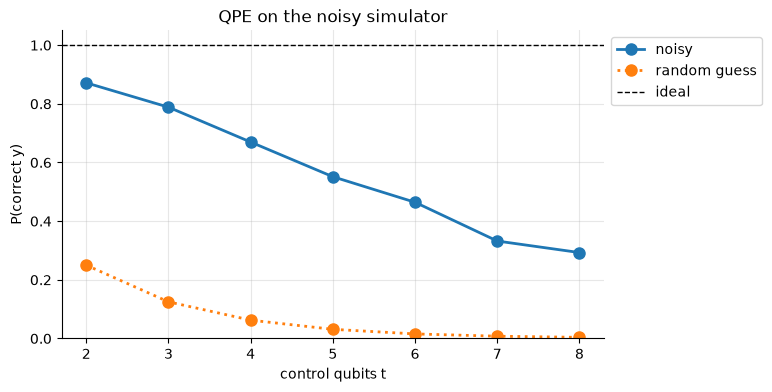

In [ ]:
ts = range(2, 9)
rows = []
for t in ts:
    y = 2**t // 3 | 1                  # an odd y: the phase really needs all t bits
    U = np.diag([1, np.exp(2j * np.pi * y / 2**t)])
    qc = qpe(U, t, one)
    cx = transpile(qc, basis_gates=basis_gates).count_ops().get('cx', 0)
    noisy = run_noisy(qc).get(f'{y:0{t}b}', 0) / shots
    rows.append((noisy, 1 / 2**t))
    print(f't = {t}: {cx:3d} CX | P(correct) noisy {noisy:.3f}, guess {1 / 2**t:.3f}')

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ts, [r[0] for r in rows], marker='o', markersize=8, linewidth=2, label='noisy')
ax.plot(ts, [r[1] for r in rows], marker='o', markersize=8, linewidth=2, linestyle=':', label='random guess')
ax.axhline(1, color='k', linewidth=1, linestyle='--', label='ideal')
ax.set_ylim(0, 1.05)
ax.set_xlabel('control qubits t')
ax.set_ylabel('P(correct y)')
ax.set_title('QPE on the noisy simulator')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
ax.grid(alpha=0.3)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.show()

## 6. Quantum counting

### 6.1 The eigenvalues of Grover's iteration

The last Grover notebook ended with an open question: $k_\text{opt}$ needs the number $M$ of marked strings, what if $M$ is unknown? QPE answers it. In the plane of the marked and unmarked states, $G = D\,Z_f$ is a rotation by $2\theta$ (04, 2.1), with $\sin^2\theta = M/N$, and you
have already seen in 5.2 that a rotation by $2\theta$ has the eigenvalues $e^{\pm 2i\theta}$. The state $|s\rangle$ lies in that plane, so it is a superposition of both eigenvectors and QPE can run directly from $|s\rangle$. We do not have to prepare the eigenvectors.

The two possible results are $\varphi = \theta/\pi$ and $\varphi = 1 - \theta/\pi$, and both give the same

$$\tilde M = N\sin^2\frac{\pi y}{2^t}$$

The oracle is the one from 04, 3.1.

In [ ]:
def grover_oracle(marked_states: list[str]) -> QuantumCircuit:
    # Phase oracle Z_f: flips the sign of every marked string, no output qubit
    num_qubits = len(marked_states[0])
    qc = QuantumCircuit(num_qubits)
    mcz = ZGate().control(num_qubits - 1)
    for target in marked_states:
        zeros = [qubit for qubit, bit in enumerate(reversed(target)) if bit == '0']
        if zeros:
            qc.x(zeros)
        qc.append(mcz, range(num_qubits))
        if zeros:
            qc.x(zeros)
    return qc


marked_states = ['0101', '1010', '1111']    # try other sets of 4-bit strings
n = len(marked_states[0])
N = 2**n
M = len(marked_states)
G = Operator(grover_operator(grover_oracle(marked_states))).data
print(f'N = {N}, M = {M}, G is a {G.shape[0]} x {G.shape[1]} matrix')

N = 16, M = 3, G is a 16 x 16 matrix


**Your turn.** Get the eigenphases of `G` with `np.angle(np.linalg.eigvals(G)) / (2 * np.pi) % 1`. Which of them are $\theta/\pi$ and $1 - \theta/\pi$ with $\theta = \arcsin\sqrt{M/N}$? The rest are 0 and $\frac12$, they belong to states outside the plane, and $|s\rangle$ has no overlap with them.

In [ ]:
# theta = ...
# phases = ...

<details>
<summary>Solution</summary>

```python
theta = math.asin(math.sqrt(M / N))
phases = np.angle(np.linalg.eigvals(G)) / (2 * np.pi) % 1

print('theta / pi =', round(theta / np.pi, 4), ', 1 - theta / pi =', round(1 - theta / np.pi, 4))
print(np.round(np.sort(phases), 4))
```

</details>

### 6.2 Counting

**Your turn.** Three lines are enough, since `qpe` takes any matrix: `prepare` is $|s\rangle$, $H$ on all $n$ qubits. Take $t = 5$, take the most frequent $y$ and compute $\tilde M$. Do not expect an integer, then increase $t$. Note that we never told the circuit how many strings are marked.

In [ ]:
t = 5

# prepare = QuantumCircuit(n)
# ...
# counts = run(qpe(G, t, prepare))

<details>
<summary>Solution</summary>

```python
t = 5

prepare = QuantumCircuit(n)
prepare.h(range(n))
counts = run(qpe(G, t, prepare))

y = int(max(counts, key=counts.get), 2)
print(f'y = {y}, M estimate = {N * math.sin(math.pi * y / 2**t)**2:.2f}')
```

</details>

In [ ]:
def estimate_M(G: np.ndarray, t: int) -> tuple[int, float]:
    n = int(np.log2(G.shape[0]))
    prepare = QuantumCircuit(n)
    prepare.h(range(n))
    counts = run(qpe(G, t, prepare))
    y = int(max(counts, key=counts.get), 2)
    return y, 2**n * math.sin(math.pi * y / 2**t)**2


print(f'true M = {M}')
for t in range(3, 8):
    y, M_estimate = estimate_M(G, t)
    print(f't = {t}: y = {y:3d}, M estimate {M_estimate:.2f}, {2**t - 1:3d} uses of G')

true M = 3


t = 3: y =   1, M estimate 2.34,   7 uses of G


t = 4: y =  14, M estimate 2.34,  15 uses of G


t = 5: y =  27, M estimate 3.56,  31 uses of G


t = 6: y =   9, M estimate 2.92,  63 uses of G


t = 7: y =  18, M estimate 2.92, 127 uses of G


### 6.3 A global phase that is not global

In 04, 1.3 we said that the diffuser built from $X$ gates and an MCZ is $-D$, and that this is only a global phase. Under a *control* it is not global any more: $C(-G)$ differs from $C(G)$ by a $Z$ on the control qubit, a relative phase, and the kickback shifts the
estimate by $\frac12$. The formula then gives $N - M$ instead of $M$.

`grover_operator` sets `global_phase = pi` for this reason, so the matrix `G` above has the right sign. Without it:

In [ ]:
for t in [5, 6]:
    print(f't = {t}: with +G {estimate_M(G, t)[1]:.2f}, with -G {estimate_M(-G, t)[1]:.2f}, N - M = {N - M}')

t = 5: with +G 3.56, with -G 12.44, N - M = 13


t = 6: with +G 2.92, with -G 13.08, N - M = 13


## 7. Shor's algorithm

### 7.1 Factoring is finding an order

Take an odd composite $N$ and some $a$ with $\gcd(a, N) = 1$. The *order* $r$ is the smallest positive number with $a^r \equiv 1 \pmod N$. If $r$ is even and $a^{r/2} \not\equiv -1 \pmod N$, then

$$\left(a^{r/2} - 1\right)\left(a^{r/2} + 1\right) = a^r - 1 \equiv 0 \pmod N$$

and $\gcd(a^{r/2} \pm 1, N)$ are factors of $N$. This reduction is entirely classical. The only quantum part of Shor's algorithm is finding $r$.

**Your turn.** For $N = 15$ and $a = 2, 4, 7, 11, 14$ find the order by trying $a^1, a^2, \dots$ (`pow(a, x, N)`), and compute the two gcds with `math.gcd`. Which $a$ give the factors, and which one does not? Why?

In [ ]:
N = 15

# for a in [2, 4, 7, 11, 14]:
#     ...

<details>
<summary>Solution</summary>

```python
N = 15

for a in [2, 4, 7, 11, 14]:
    r = 1
    while pow(a, r, N) != 1:
        r += 1
    half = pow(a, r // 2, N)
    print(f'a = {a:2d}: r = {r}, a^(r/2) = {half:2d}, gcds {math.gcd(half - 1, N)}, {math.gcd(half + 1, N)}')
```

</details>

### 7.2 Multiplication as a unitary

Multiplying by $a$ modulo $N$ is a unitary on the states $|y\rangle$, since for $\gcd(a, N) = 1$ it is a permutation:

$$U_a|y\rangle = |ay \bmod N\rangle$$

Applied to $|1\rangle$ it walks in a cycle of length $r$, the order. On that cycle its eigenstates are the discrete waves $|u_s\rangle = \frac{1}{\sqrt r}\sum_\ell e^{-2\pi i s\ell/r}|a^\ell \bmod N\rangle$, with eigenvalues $e^{2\pi i s/r}$. So the phases of $U_a$ are multiples of $1/r$, and QPE can read them.

We build $U_a$ as a matrix, on $\lceil\log_2 N\rceil$ qubits. The states $y \ge N$ are left alone.

In [ ]:
def modmul_matrix(a: int, N: int) -> np.ndarray:
    d = 2**math.ceil(math.log2(N))
    U = np.zeros((d, d))
    for y in range(d):
        U[a * y % N if y < N else y, y] = 1
    return U


a, N = 7, 15
cycle = [1]
while pow(a, len(cycle), N) != 1:
    cycle.append(pow(a, len(cycle), N))
print(' -> '.join(map(str, cycle + [1])))

phases = np.angle(np.linalg.eigvals(modmul_matrix(a, N))) / (2 * np.pi) % 1
print('phases of U_a:', sorted({float(round(p, 4)) for p in phases}))

1 -> 7 -> 4 -> 13 -> 1
phases of U_a: [0.0, 0.25, 0.5, 0.75]


### 7.3 QPE from $|1\rangle$

We cannot prepare $|u_s\rangle$ without knowing $r$. We do not need to: the equal superposition of all $|u_s\rangle$ is $|1\rangle$, which is trivial to prepare. So QPE started from $|1\rangle$ gives $y/2^t \approx s/r$ for a random $s$. It is the same trick as starting from $|s\rangle$ in section 6, and as $|01\rangle$ in 5.4.

**Your turn.** Find the order of $a = 7$ modulo $15$ with `qpe(modmul_matrix(7, 15), t, prepare)`, where `prepare` has 4 qubits with $X$ on $q_0$ (that is $|1\rangle$), and $t = 8$. Which values of $y$ come out, and what are they as fractions of $2^t$? Try $a = 4$ and $a = 11$ as well.

In [ ]:
a, N, t = 7, 15, 8

# prepare = QuantumCircuit(4)
# ...

<details>
<summary>Solution</summary>

```python
a, N, t = 7, 15, 8

prepare = QuantumCircuit(4)
prepare.x(0)
counts = run(qpe(modmul_matrix(a, N), t, prepare))

for key, value in sorted(counts.items()):
    print(f'y = {int(key, 2):3d}, y / 2^t = {Fraction(int(key, 2), 2**t)}, {value} shots')
```

</details>

### 7.4 Continued fractions

For $N = 15$ the peaks are exact, because $r = 4$ is a power of 2. That is a lucky special case. In general $y/2^t$ is only close to $s/r$, and we have to recover a fraction with a small denominator. Choosing $2^t \ge N^2$ guarantees that $s/r$ is a convergent of the continued fraction of $y/2^t$, and
`Fraction(y, 2**t).limit_denominator(N)` gives the closest one with denominator below $N$.

The denominator is only a *candidate*: if $s$ and $r$ have a common factor, the fraction is reduced and the denominator is too small. Each candidate is therefore checked with $a^{r'} \equiv 1 \pmod N$, which is classical and easy.

The first honest example is $N = 21$, $a = 2$, with $r = 6$. That is 15 qubits with $t = 9$ control qubits: $2^9 = 512 \ge 21^2$. (The cell runs for a few seconds.)

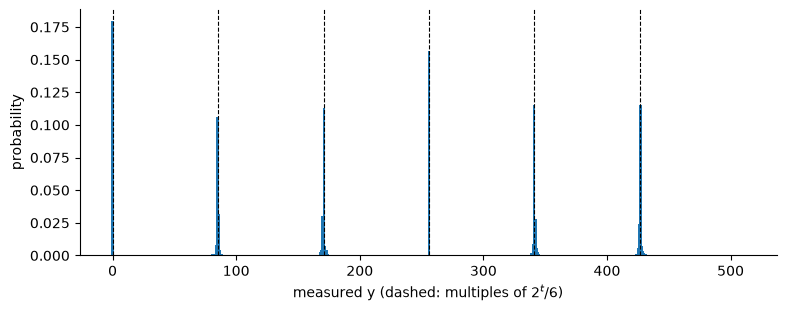

  y | y / 2^t | fraction | candidate r | a^r = 1 mod N | shots
  0 |  0.0000 |        0 |           1 |         False | 736
256 |  0.5000 |      1/2 |           2 |         False | 642
341 |  0.6660 |      2/3 |           3 |         False | 473
427 |  0.8340 |      5/6 |           6 |          True | 471
171 |  0.3340 |      1/3 |           3 |         False | 464
 85 |  0.1660 |      1/6 |           6 |          True | 435
 86 |  0.1680 |      1/6 |           6 |          True | 131
170 |  0.3320 |      1/3 |           3 |         False | 124


In [ ]:
def order_candidate(y: int, t: int, a: int, N: int) -> tuple[Fraction, bool]:
    fraction = Fraction(y, 2**t).limit_denominator(N)
    return fraction, pow(a, fraction.denominator, N) == 1


a, N, t = 2, 21, 9
n = math.ceil(math.log2(N))
prepare = QuantumCircuit(n)
prepare.x(0)
counts = run(qpe(modmul_matrix(a, N), t, prepare))

measured = np.array([counts.get(f'{y:0{t}b}', 0) / shots for y in range(2**t)])
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(range(2**t), measured, width=2)
for s in range(6):
    ax.axvline(s * 2**t / 6, color='k', linestyle='--', linewidth=0.8)
ax.set_xlabel('measured y (dashed: multiples of $2^t / 6$)')
ax.set_ylabel('probability')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.show()

print('  y | y / 2^t | fraction | candidate r | a^r = 1 mod N | shots')
for key, value in sorted(counts.items(), key=lambda item: -item[1])[:8]:
    y = int(key, 2)
    fraction, valid = order_candidate(y, t, a, N)
    print(f'{y:3d} | {y / 2**t:7.4f} | {str(fraction):>8} | {fraction.denominator:11d} | {str(valid):>13} | {value}')

The peaks sit around the multiples of $2^t/6$, as in the periodic state with $Q/r$ not an integer from 4.5. That is no coincidence: Shor's original description was exactly that, a periodic state of $f(x) = a^x \bmod N$ and a QFT. The circuit is the same, only the explanation differs.

Only the peaks at $s = 1, 5$ give $r = 6$ directly. The others have a common factor with 6 and give 3, 2 or 1, and the check rejects them. Then we simply run the circuit again.

### 7.5 The whole algorithm

The steps from the textbook: pick a random $a$, find the order, check it, compute the factors, repeat if something failed. A random $a$ that shares a factor with $N$ would finish the job right away. We skip that luck so that the quantum part always runs. Note how little of the algorithm is quantum. (The cell runs for a few seconds to a minute, depending on your luck.)

In [ ]:
def shor(N: int, max_tries: int = 20) -> tuple[int, int] | None:
    if N % 2 == 0:
        return 2, N // 2
    n = math.ceil(math.log2(N))
    t = math.ceil(2 * math.log2(N))    # 2^t >= N^2
    prepare = QuantumCircuit(n)
    prepare.x(0)

    for attempt in range(1, max_tries + 1):
        a = random.randrange(2, N)
        d = math.gcd(a, N)
        if d > 1:
            print(f'{attempt}. a = {a}: gcd = {d} is already a factor, a real run would stop here')
            continue

        y = int(list(run(qpe(modmul_matrix(a, N), t, prepare), shots=1))[0], 2)
        fraction, valid = order_candidate(y, t, a, N)
        r = fraction.denominator
        if not valid:
            print(f'{attempt}. a = {a}: y = {y} gives r = {r}, which is not the order, repeat')
        elif r % 2 == 1 or pow(a, r // 2, N) == N - 1:
            print(f'{attempt}. a = {a}: order r = {r} is of no use, take another a')
        else:
            half = pow(a, r // 2, N)
            print(f'{attempt}. a = {a}: order r = {r}, a^(r/2) = {half}')
            return math.gcd(half - 1, N), math.gcd(half + 1, N)
    return None


for N in [15, 21]:
    print(f'N = {N}: factors {shor(N)}\n')

1. a = 9: gcd = 3 is already a factor, a real run would stop here
2. a = 3: gcd = 3 is already a factor, a real run would stop here
3. a = 12: gcd = 3 is already a factor, a real run would stop here


4. a = 13: order r = 4, a^(r/2) = 4
N = 15: factors (3, 5)



1. a = 20: y = 0 gives r = 1, which is not the order, repeat


2. a = 17: y = 256 gives r = 2, which is not the order, repeat


3. a = 4: order r = 3 is of no use, take another a


4. a = 4: order r = 3 is of no use, take another a


5. a = 16: y = 0 gives r = 1, which is not the order, repeat


6. a = 5: y = 256 gives r = 2, which is not the order, repeat
7. a = 15: gcd = 3 is already a factor, a real run would stop here


8. a = 19: order r = 6, a^(r/2) = 13
N = 21: factors (3, 7)



### 7.6 What this demonstration is not

Honesty is needed here. Our $U_a$ is a matrix with a column for every $y$, so writing it down took as much work as the whole problem, and it is only possible for very small $N$. The real algorithm computes $a^{2^k}y \bmod N$ with reversible arithmetic circuits, and that arithmetic
makes up most of the gates of Shor's algorithm. It is also why the powers are cheap here: $a^{2^k} \bmod N$ can be computed by repeated squaring, so $U_a^{2^k}$ is just one more multiplication. This is the shortcut 5.5 asked for.

Even for $N = 15$ the compiled circuit is out of reach of our noise model:

In [ ]:
prepare = QuantumCircuit(4)
prepare.x(0)
qc = qpe(modmul_matrix(7, 15), 8, prepare)
cx = transpile(qc, basis_gates=basis_gates).count_ops().get('cx', 0)

print(f'{qc.num_qubits} qubits, {cx} CX gates')
print(f'probability that no CX fails: {(1 - p_2q)**cx:.1e}')

12 qubits, 537 CX gates
probability that no CX fails: 3.0e-04


**Questions**

- Why does the interferometer in 1.1 not tell $\alpha$ from $-\alpha$? How would you add $S^\dagger$ before the last $H$ to fix that?
- What is the state of the control qubit in 2.1 for a general input $a|0\rangle + b|1\rangle$?
- Run `iterative_qpe` with $\varphi = 1/3$. Why is no bit certain any more, and which $y$ wins?
- Prepare a periodic state with period 4 in a register of size 16 and simulate its QFT. Explain the positions of the peaks.
- Why can we not read all the Fourier coefficients of a state from the QFT in $O(n^2)$ gates?
- In 5.3, what do you get for $\varphi = 1/3$ with $t = 8$ if you reverse the bits of the result? Why?
- In 5.4, choose a system state that gives $y = 1$ and $y = 5$ with probabilities $\frac14$ and $\frac34$.
- For $N = 4$ and $M = 2$, compute $\theta$ and the eigenvalues of $G$ by hand. Which $y$ does QPE give with $t = 2$?
- What does quantum counting give if no string is marked? Try `G` with an oracle that does nothing.
- Which of the steps of `shor` needs a quantum computer? Could you replace it by a classical loop for $N = 15$? And for a 2048-bit $N$?
- Take $y/2^t = 11/32$ and compute the continued fraction by hand. Which candidates for $s/r$ do you get?